# Detecting Hidden Data Leakage Without Knowing the Pipeline
### An automated framework based on dataset and model behaviour — **California Housing** benchmark

**Jackfruit Project (ADA)** · Team: **Akula Pragnya** (PES1UG24AM028), **Abhay TS** (PES1UG24AM008), **Avyukt Ranjan** (PES1UG24AM060)

---

## Problem
ML results are often inflated by data leakage, yet finding it normally requires full knowledge of the training pipeline. This notebook builds an **automated, pipeline-agnostic detector** that sees only

* the processed train / test splits exactly as given to the model (features, labels, optional timestamp column), and
* the trained model as a **black box** (`predict` / `predict_proba` only) — no code, no logs, no pipeline details,

and measures how reliably it finds **controlled, injected** leakage on the California Housing data with four model families (Logistic Regression, Random Forest, XGBoost, MLP).

## Leakage types and what applies to this dataset
| # | Leakage type | Injected here? | How |
|---|---|---|---|
| 1 | **Target leakage** – a feature encodes / is derived from the label | ✅ | extra column `leak_feat = y + N(0, σ)`, σ ∈ {1.0, 0.5, 0.15} |
| 2 | **Train–test contamination** – test rows duplicated / near-duplicated in train | ✅ | 1 % / 5 % / 20 % of test rows copied into train (exact and near copies) |
| 3 | **Temporal leakage** – training uses data from after the test period | ❌ **N/A** | California Housing has **no time axis**. The module abstains here (`score = NaN`, `flag = False`) and is unit-tested on *synthetic* timestamps (cell 17) outside the reported results. No fake time axis is invented. |
| 4 | **Preprocessing leakage** – scaling / imputation / encoding fitted on train + test | ✅ | scaler; scaler + imputer; scaler + imputer + frequency-encoder fitted on train + test (the last one only if the file has a categorical column) |

## Detector output (per leakage type)
a leakage **score (0–1)**, a binary **flag**, the **evidence** (suspect features, duplicate row IDs, fingerprints), an overall **verdict** (`clean` / `leaky`) and an **estimated performance inflation**. Signals used: feature–target mutual information, duplicate overlap, adversarial validation, feature ablation, permutation importance, exact scaler / imputer / encoder fingerprints and train–test confidence gaps.

## How to run
1. Upload your housing file to `/content` (any CSV/XLSX with “housing” in its name is found automatically). Two schemas are auto-detected:
   **Kaggle** (`longitude, latitude, housing_median_age, total_rooms, total_bedrooms, population, households, median_income, median_house_value, ocean_proximity`) or **scikit-learn** (`MedInc, HouseAge, AveRooms, AveBedrms, Population, AveOccup, Latitude, Longitude, MedHouseVal`).
2. **Runtime → Run all.** CPU runtime is enough, no Google Drive needed.
3. Outputs go to `/content/results/` (`results.csv`, `results_with_inflation.csv`, `thresholds.json`, `tables/`, `figures/`) and are zipped for download in the last cell.
4. Set `CFG["QUICK_MODE"] = True` in cell 3 for a smoke run (4 seeds, fewer trees). The benchmark checkpoints after every scenario and **resumes** automatically if the session restarts.

> **Runtime.** The full benchmark is 9–10 scenarios × 4 models × 10 seeds, plus threshold calibration (5 extra seeds). In a test run on a single CPU core, one seed across all 10 scenarios took about 3 minutes and calibration about 6 minutes, so expect roughly **30–60 minutes on a free Colab CPU** for `N_SEEDS = 10` (real XGBoost is somewhat slower than the stand-in used in that test). `QUICK_MODE` takes roughly half of that.

## Key design decisions
1. **Classification target.** `y = 1` if median house value > the global median (fixed once ⇒ classes ≈ 50/50, identical in every scenario). Needed because Logistic Regression and `predict_proba` require a class label.
2. **Split.** Stratified random 60 / 20 / 20 train / validation / test, redrawn for every seed. The validation set is used only for XGBoost early stopping and the practitioner check (cell 32). **The detector never sees it.**
3. **Missing values.** A fixed MCAR mask (≥ 5 % in `rooms`, `bedrooms`, `population`, seed 2024) is applied once before splitting so imputation exists in every scenario and its fingerprint can be tested. It is data, not a leak.
4. **Clean twin.** Every leaky scenario is compared with the `clean` scenario of the same seed (same split, same test rows). True inflation = metric(leaky) − metric(clean).
5. **Scaling and mean imputation are present in *every* scenario**, so the detector cannot separate clean from leaky just from the presence of scaling.
6. **Thresholds** are calibrated on disjoint seeds (100–104) and frozen *before* the evaluation seeds (0–9) are run.

## Known caveats (stated up-front)
* **Temporal leakage is not evaluated** for this dataset (no time axis) and is reported as N/A.
* The `clean` scenario is clean **only with respect to the four injected leak types**. A random split of geographic data puts neighbouring blocks in train and test — a natural, uninjected spatial optimism (illustrated in cell 34).
* Price is capped at 500,001 in the Kaggle file; the label is unaffected because it uses a median threshold.
* Wilson confidence intervals treat every (seed, scenario, model) run as independent, but the four models of one scenario share the same data-level evidence, so the intervals are somewhat optimistic.
* Preprocessing leakage barely changes accuracy; it is detected from exact fingerprints, **not** from performance.

---
# PART A — Setup and data
Imports, configuration, loading with schema auto-detection, EDA, label construction and the split builder.

In [1]:
# ===================================================================
# PART A — SETUP AND DATA
# Cell 2 — Installs and imports (no Google Drive)
# ===================================================================
import importlib, subprocess, sys, os, glob, json, gc, time, hashlib, warnings, math
from dataclasses import dataclass, field

def _ensure(pip_name, import_name=None):
    """pip-install a package only if it cannot be imported."""
    try:
        importlib.import_module(import_name or pip_name)
    except ImportError:
        print(f"Installing {pip_name} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])

_ensure("xgboost")
_ensure("tqdm")

import numpy as np
import pandas as pd
import scipy
from scipy import stats
import sklearn
import xgboost
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, GroupKFold, KFold, cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, log_loss, roc_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import mutual_info_classif
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titleweight": "bold"})

# ---- folders -------------------------------------------------------
ROOT = "/content" if os.path.isdir("/content") else os.getcwd()     # Colab, or local Jupyter fallback
RESULTS_DIR = os.path.join(ROOT, "results")
FIG_DIR     = os.path.join(RESULTS_DIR, "figures")
TABLE_DIR   = os.path.join(RESULTS_DIR, "tables")
for _d in (RESULTS_DIR, FIG_DIR, TABLE_DIR):
    os.makedirs(_d, exist_ok=True)

# ---- environment report -------------------------------------------
def _ram_gb():
    try:
        import psutil
        return psutil.virtual_memory().total / 2**30
    except Exception:
        try:
            return os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30
        except Exception:
            return float("nan")

print("Python      :", sys.version.split()[0])
for _m in (np, pd, scipy, sklearn, xgboost, matplotlib, sns):
    print(f"{_m.__name__:<11}:", _m.__version__)
print("CPU count   :", os.cpu_count())
print(f"RAM         : {_ram_gb():.1f} GB")
print("Working dir :", ROOT)
print("Results dir :", RESULTS_DIR)

Python      : 3.13.18
numpy      : 2.1.3
pandas     : 2.2.3
scipy      : 1.16.3
sklearn    : 1.6.1
xgboost    : 3.4.1
matplotlib : 3.10.0
seaborn    : 0.13.2
CPU count   : 2
RAM         : 12.7 GB
Working dir : /content
Results dir : /content/results


In [2]:
# ===================================================================
# Cell 3 — Configuration `CFG` (every tunable value lives here)
# ===================================================================
CFG = dict(
    # ---------------- data ----------------
    DATA_PATH=os.path.join(ROOT, "california_housing.csv"),   # auto-search in ROOT if missing (cell 4)

    # ---------------- run size ------------
    QUICK_MODE=False,            # True -> N_SEEDS=4, fewer trees, 3 calibration seeds (smoke run)
    N_SEEDS=10,
    CAL_SEEDS=[100, 101, 102, 103, 104],      # calibration seeds: disjoint from the evaluation seeds
    MASK_SEED=2024,
    RESUME=True,                 # resume results.csv if present (False -> start from scratch)

    # ---------------- split / missingness -------------
    SPLIT=(0.6, 0.2, 0.2),       # train / validation / test
    MCAR_RATE=0.05,
    MCAR_COLS=["rooms", "bedrooms", "population"],   # canonical names
    #   Kaggle: total_rooms, total_bedrooms, population   |   sklearn: AveRooms, AveBedrms, Population

    # ---------------- detector constants --------
    MI_SUBSAMPLE=20000,
    NN_QUERY=4000,               # effective value: min(NN_QUERY, len(test))
    NN_HOLDOUT=4000,             # effective value: min(NN_HOLDOUT, len(train)//3)
    ADV_SUBSAMPLE=20000,
    PERM_ROWS=4000,
    PERM_REPEATS=3,
    TOP_K=5,
    ROUND_DECIMALS=6,
    FP_TOL=1e-7,
    NEW_ID_BASE=10_000_000,      # row_ids given to injected train copies (so ids never reveal the leak)

    # ---------------- thresholds (raised only by cell 24, then frozen) --------
    THRESH=dict(target=0.5, contamination=0.5, temporal=0.5, preprocessing=0.5),

    LEAK_TYPES=["target", "contamination", "temporal", "preprocessing"],
    EVALUATED_TYPES=["target", "contamination", "preprocessing"],   # temporal is N/A (no timestamp)
    MODELS=["logreg", "rf", "xgb", "mlp"],

    # ---------------- scenario matrix (per seed) ------------------
    # params keys:  sigma -> target leak | p, near_frac -> contamination | scopes -> preprocessing fit scope
    SCENARIOS={
        "clean":     dict(type="none",          variant="-", params={}),
        "target_L":  dict(type="target",        variant="L", params=dict(sigma=1.0)),
        "target_M":  dict(type="target",        variant="M", params=dict(sigma=0.5)),
        "target_H":  dict(type="target",        variant="H", params=dict(sigma=0.15)),
        "contam_L":  dict(type="contamination", variant="L", params=dict(p=0.01, near_frac=0.0)),   # all exact
        "contam_M":  dict(type="contamination", variant="M", params=dict(p=0.05, near_frac=0.5)),
        "contam_H":  dict(type="contamination", variant="H", params=dict(p=0.20, near_frac=0.5)),
        "prep_L":    dict(type="preprocessing", variant="L", params=dict(scopes=dict(scale="pool"))),
        "prep_M":    dict(type="preprocessing", variant="M", params=dict(scopes=dict(scale="pool", impute="pool"))),
        "prep_H":    dict(type="preprocessing", variant="H", needs_cat=True,
                          params=dict(scopes=dict(scale="pool", impute="pool", encode="pool"))),
    },
)
if CFG["QUICK_MODE"]:
    CFG["N_SEEDS"] = 4
    CFG["CAL_SEEDS"] = CFG["CAL_SEEDS"][:3]
CFG["EVAL_SEEDS"] = list(range(CFG["N_SEEDS"]))
assert not set(CFG["EVAL_SEEDS"]) & set(CFG["CAL_SEEDS"]), "calibration and evaluation seeds must be disjoint"

print("QUICK_MODE :", CFG["QUICK_MODE"], "| evaluation seeds:", CFG["EVAL_SEEDS"], "| calibration seeds:", CFG["CAL_SEEDS"])
print("Scenarios  :", list(CFG["SCENARIOS"]))

QUICK_MODE : False | evaluation seeds: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | calibration seeds: [100, 101, 102, 103, 104]
Scenarios  : ['clean', 'target_L', 'target_M', 'target_H', 'contam_L', 'contam_M', 'contam_H', 'prep_L', 'prep_M', 'prep_H']


In [3]:
# ===================================================================
# Cell 4 — Load the file and detect the schema (Kaggle vs scikit-learn layout)
# ===================================================================
def locate_data_file(path):
    """Use `path` if it exists, otherwise search ROOT for a .csv/.xlsx whose name contains 'housing'."""
    if os.path.exists(path):
        return path
    candidates = sorted(f for ext in ("*.csv", "*.xlsx", "*.xls") for f in glob.glob(os.path.join(ROOT, ext)))
    hits = [f for f in candidates if "housing" in os.path.basename(f).lower()]
    if hits:
        if len(hits) > 1:
            print("More than one candidate found, using the first:", [os.path.basename(h) for h in hits])
        return hits[0]
    raise FileNotFoundError(
        f"No housing file found. Expected '{path}' or any .csv/.xlsx with 'housing' in its name in {ROOT}.\n"
        f"Files found there: {[os.path.basename(f) for f in candidates] or '(no csv/xlsx files)'}\n"
        "Upload your file to /content (left sidebar -> Files -> Upload) and re-run this cell.")

def read_table(path):
    """CSV by default; Excel if the extension says so OR the file starts with the zip magic bytes (a renamed .xlsx)."""
    with open(path, "rb") as fh:
        head = fh.read(4)
    if head.startswith(b"PK") or path.lower().endswith((".xlsx", ".xls")):
        return pd.read_excel(path)
    return pd.read_csv(path)

DATA_FILE = locate_data_file(CFG["DATA_PATH"])
df_orig = read_table(DATA_FILE)
df_orig.columns = [str(c).strip() for c in df_orig.columns]
print(f"Loaded {os.path.basename(DATA_FILE)}  ->  {df_orig.shape[0]:,} rows x {df_orig.shape[1]} columns")
print("Columns:", list(df_orig.columns))
display(df_orig.head(3))

KAGGLE_MAP = {"longitude": "longitude", "latitude": "latitude", "housing_median_age": "housing_age",
              "total_rooms": "rooms", "total_bedrooms": "bedrooms", "population": "population",
              "households": "households_or_occupancy", "median_income": "median_income",
              "median_house_value": "price", "ocean_proximity": "ocean_proximity"}
SKLEARN_MAP = {"longitude": "longitude", "latitude": "latitude", "houseage": "housing_age",
               "averooms": "rooms", "avebedrms": "bedrooms", "population": "population",
               "aveoccup": "households_or_occupancy", "medinc": "median_income", "medhouseval": "price"}

_lower = {c.lower(): c for c in df_orig.columns}
if "median_house_value" in _lower or "ocean_proximity" in _lower:
    SCHEMA, _map = "kaggle", KAGGLE_MAP
elif "medhouseval" in _lower:
    SCHEMA, _map = "sklearn", SKLEARN_MAP
else:
    raise ValueError("Unrecognised schema: expected 'median_house_value' (Kaggle) or 'MedHouseVal' (scikit-learn). "
                     f"Columns found: {list(df_orig.columns)}")

REQUIRED = [k for k in _map if k != "ocean_proximity"]
_missing = [k for k in REQUIRED if k not in _lower]
assert not _missing, f"{SCHEMA} schema detected but columns are missing: {_missing}"

ORIG_NAME_MAP = {}                              # canonical name -> original column name
_rename = {}
for k, canon in _map.items():
    if k in _lower:
        _rename[_lower[k]] = canon
        ORIG_NAME_MAP[canon] = _lower[k]
df_raw = df_orig[list(_rename)].rename(columns=_rename).copy()
HAS_CATEGORICAL = "ocean_proximity" in df_raw.columns
if HAS_CATEGORICAL:
    df_raw["ocean_proximity"] = df_raw["ocean_proximity"].astype("object")
df_raw = df_raw.dropna(subset=["price"]).reset_index(drop=True)

print(f"\nDetected schema   : {SCHEMA}")
print(f"HAS_CATEGORICAL   : {HAS_CATEGORICAL}  ->  prep_H (encoder leakage) scenario {'ENABLED' if HAS_CATEGORICAL else 'SKIPPED (no categorical column)'}")
print("Canonical columns :", list(df_raw.columns))
print("Original names    :", ORIG_NAME_MAP)
n = len(df_raw)
print(f"Row count         : {n:,}  ({'OK, close to 20,640' if abs(n - 20640) <= 1000 else 'WARNING: expected about 20,640 rows'})")

Loaded california_housing.csv  ->  20,640 rows x 9 columns
Columns: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521



Detected schema   : sklearn
HAS_CATEGORICAL   : False  ->  prep_H (encoder leakage) scenario SKIPPED (no categorical column)
Canonical columns : ['longitude', 'latitude', 'housing_age', 'rooms', 'bedrooms', 'population', 'households_or_occupancy', 'median_income', 'price']
Original names    : {'longitude': 'Longitude', 'latitude': 'Latitude', 'housing_age': 'HouseAge', 'rooms': 'AveRooms', 'bedrooms': 'AveBedrms', 'population': 'Population', 'households_or_occupancy': 'AveOccup', 'median_income': 'MedInc', 'price': 'MedHouseVal'}
Row count         : 20,640  (OK, close to 20,640)


Missing values (natural, before the MCAR top-up in cell 6):


,n_missing,pct_missing
longitude,0,0.0
latitude,0,0.0
housing_age,0,0.0
rooms,0,0.0
bedrooms,0,0.0
population,0,0.0
households_or_occupancy,0,0.0
median_income,0,0.0
price,0,0.0


Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.570,2.004,-124.350,-121.800,-118.490,-118.010,-114.310
latitude,20640.0,35.632,2.136,32.540,33.930,34.260,37.710,41.950
housing_age,20640.0,28.639,12.586,1.000,18.000,29.000,37.000,52.000
rooms,20640.0,5.429,2.474,0.846,4.441,5.229,6.052,141.909
bedrooms,20640.0,1.097,0.474,0.333,1.006,1.049,1.100,34.067
population,20640.0,1425.477,1132.462,3.000,787.000,1166.000,1725.000,35682.000
households_or_occupancy,20640.0,3.071,10.386,0.692,2.430,2.818,3.282,1243.333
median_income,20640.0,3.871,1.900,0.500,2.563,3.535,4.743,15.000
price,20640.0,2.069,1.154,0.150,1.196,1.797,2.647,5.000



Duplicate rows in the raw file: 0  (expected 0)
Known caps: price capped at 5 -> 965 rows (4.7%); housing age capped at 52 -> 1,273 rows (6.2%).
(The label uses a median threshold, so the price cap does not change it.)


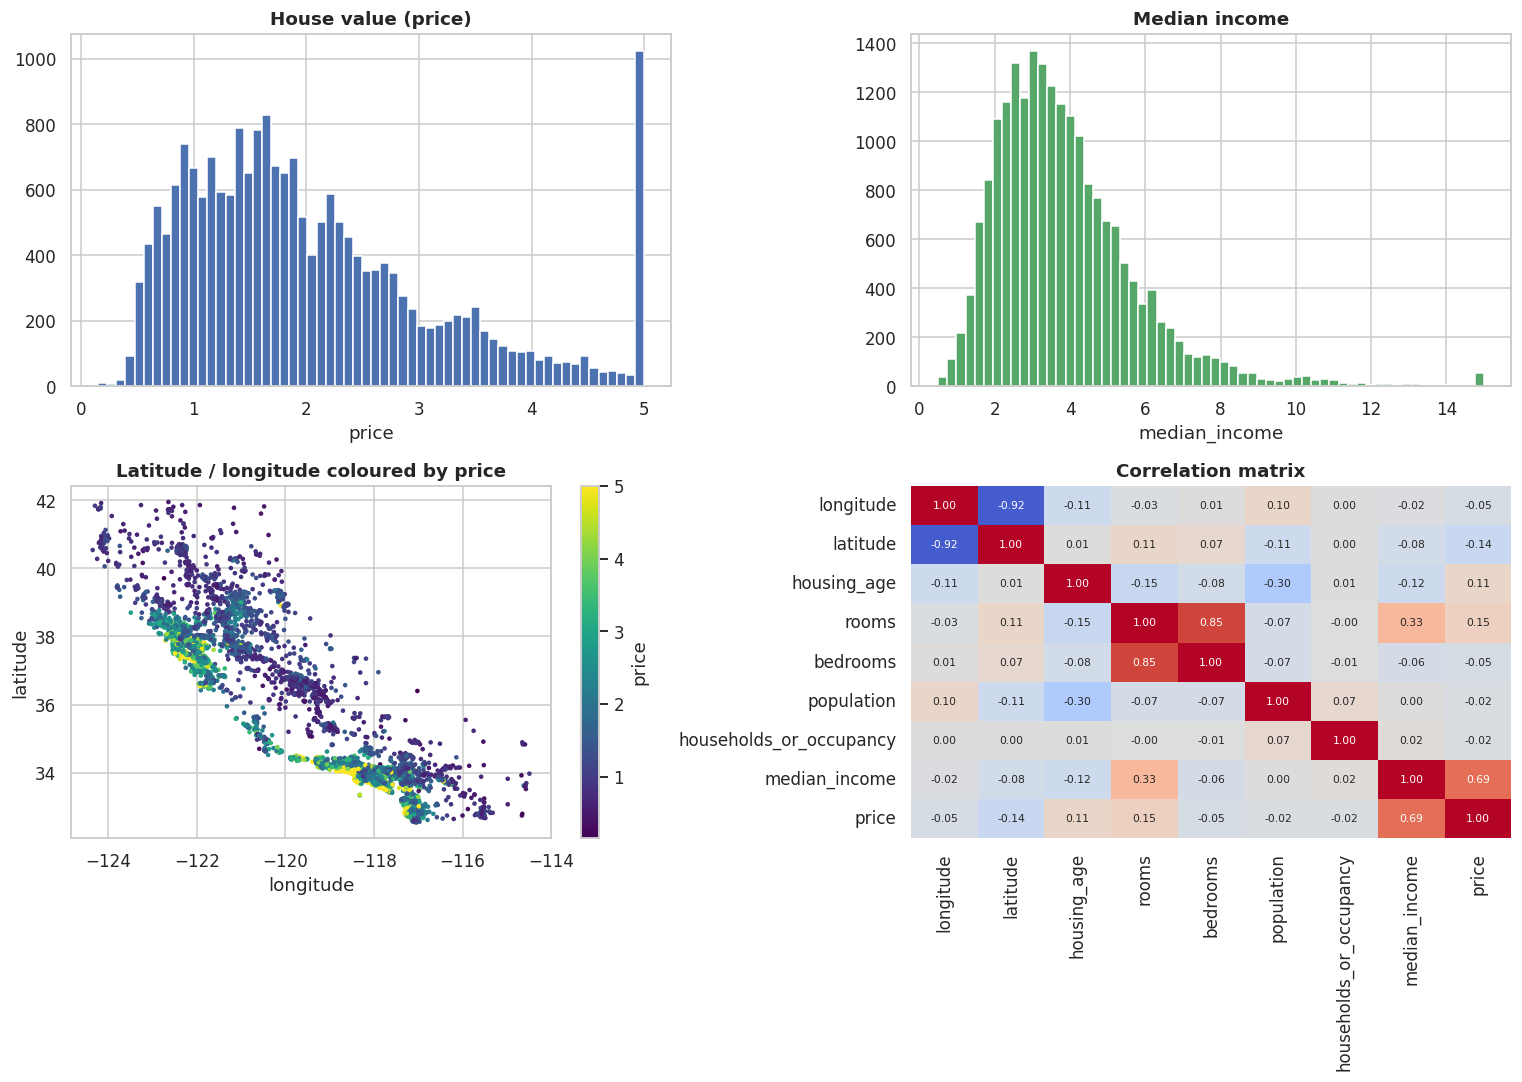

In [4]:
# ===================================================================
# Cell 5 — Validation and EDA
# ===================================================================
miss = df_raw.isna().sum().to_frame("n_missing")
miss["pct_missing"] = (100 * miss["n_missing"] / len(df_raw)).round(2)
print("Missing values (natural, before the MCAR top-up in cell 6):")
display(miss)
print("Descriptive statistics:")
display(df_raw.describe().T.round(3))

N_DUP_ROWS = int(df_raw.drop(columns=[]).duplicated().sum())
print(f"\nDuplicate rows in the raw file: {N_DUP_ROWS}  (expected 0)")

price_cap, age_cap = df_raw["price"].max(), df_raw["housing_age"].max()
n_price_cap = int((df_raw["price"] == price_cap).sum())
n_age_cap = int((df_raw["housing_age"] == age_cap).sum())
print(f"Known caps: price capped at {price_cap:,.5g} -> {n_price_cap:,} rows ({100*n_price_cap/len(df_raw):.1f}%); "
      f"housing age capped at {age_cap:g} -> {n_age_cap:,} rows ({100*n_age_cap/len(df_raw):.1f}%).")
print("(The label uses a median threshold, so the price cap does not change it.)")

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
ax[0, 0].hist(df_raw["price"], bins=60, color="#4C72B0"); ax[0, 0].set_title("House value (price)"); ax[0, 0].set_xlabel("price")
ax[0, 1].hist(df_raw["median_income"], bins=60, color="#55A868"); ax[0, 1].set_title("Median income"); ax[0, 1].set_xlabel("median_income")
sub = df_raw.sample(min(len(df_raw), 12000), random_state=0)
sc = ax[1, 0].scatter(sub["longitude"], sub["latitude"], c=sub["price"], s=4, cmap="viridis")
ax[1, 0].set_title("Latitude / longitude coloured by price"); ax[1, 0].set_xlabel("longitude"); ax[1, 0].set_ylabel("latitude")
plt.colorbar(sc, ax=ax[1, 0], label="price")
num_for_corr = df_raw.select_dtypes(include=[np.number])
sns.heatmap(num_for_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1, 1], cbar=False, annot_kws={"size": 7})
ax[1, 1].set_title("Correlation matrix")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "00_eda.png"), bbox_inches="tight")
plt.show()

In [5]:
# ===================================================================
# Cell 6 — Feature preparation, label, missingness top-up
# ===================================================================
data = df_raw.copy().reset_index(drop=True)
data.insert(0, "row_id", np.arange(len(data)))                    # 1. unique row id

PRICE_MEDIAN = float(data["price"].median())                      # 2. label: computed once on the full data
data["y"] = (data["price"] > PRICE_MEDIAN).astype(int)           #    (a label rule only, no feature statistic)

CAT_COLS = ["ocean_proximity"] if HAS_CATEGORICAL else []         # 3. column groups
NUM_COLS = [c for c in data.columns if c not in ("row_id", "price", "y", *CAT_COLS)]
CONT_RAW = list(NUM_COLS)                                         # all numeric -> used for near-duplicate jitter
FEATURE_COLS = CAT_COLS + NUM_COLS

# 4. fixed MCAR mask: reach >= MCAR_RATE missing in each configured column (natural NaNs are kept)
mask_rng = np.random.default_rng(CFG["MASK_SEED"])
for col in CFG["MCAR_COLS"]:
    assert col in data.columns, f"MCAR column {col!r} not found"
    target_n = int(math.ceil(CFG["MCAR_RATE"] * len(data)))
    already = int(data[col].isna().sum())
    if already < target_n:
        observed = np.flatnonzero(data[col].notna().to_numpy())
        pick = mask_rng.choice(observed, size=target_n - already, replace=False)
        data.loc[pick, col] = np.nan
miss_rate = data[CFG["MCAR_COLS"]].isna().mean().round(4)
print("Final missing rate per masked column:\n", miss_rate.to_string())
print("Other columns with NaN:", [c for c in FEATURE_COLS if c not in CFG["MCAR_COLS"] and data[c].isna().any()] or "none")

price_series = data["price"].copy()                               # kept only for reference / EDA
data = data.drop(columns=["price"])                               # 5. price must never be a feature

assert "price" not in data.columns
assert abs(data["y"].mean() - 0.5) < 0.05, f"label balance off: {data['y'].mean():.3f}"
print(f"\nLabel rule: y = 1 if price > {PRICE_MEDIAN:,.4f}   |   mean(y) = {data['y'].mean():.4f}")
print("Categorical columns :", CAT_COLS or "none")
print("Numeric columns     :", NUM_COLS)
print("`data` shape        :", data.shape, "(row_id + features + y)")

Final missing rate per masked column:
 rooms         0.05
bedrooms      0.05
population    0.05
Other columns with NaN: none

Label rule: y = 1 if price > 1.7970   |   mean(y) = 0.4999
Categorical columns : none
Numeric columns     : ['longitude', 'latitude', 'housing_age', 'rooms', 'bedrooms', 'population', 'households_or_occupancy', 'median_income']
`data` shape        : (20640, 10) (row_id + features + y)


In [6]:
# ===================================================================
# Cell 7 — Split builder (stratified 60 / 20 / 20, redrawn for every seed)
# ===================================================================
def make_split(seed):
    """Return (train, val, test) DataFrames. The same seed always gives the same split."""
    idx = np.arange(len(data))
    y_all = data["y"].to_numpy()
    f_train, f_val, f_test = CFG["SPLIT"]
    tr_idx, rest_idx = train_test_split(idx, test_size=f_val + f_test, stratify=y_all, random_state=seed)
    val_idx, te_idx = train_test_split(rest_idx, test_size=f_test / (f_val + f_test), stratify=y_all[rest_idx], random_state=seed)
    take = lambda ii: data.iloc[np.sort(ii)].reset_index(drop=True)
    return take(tr_idx), take(val_idx), take(te_idx)

# ---- checks ---------------------------------------------------------
_tr, _va, _te = make_split(0)
_ids = [set(d["row_id"]) for d in (_tr, _va, _te)]
assert not (_ids[0] & _ids[1]) and not (_ids[0] & _ids[2]) and not (_ids[1] & _ids[2]), "row_id overlap between splits"
assert len(_ids[0]) + len(_ids[1]) + len(_ids[2]) == len(data), "split does not cover the data"
_bal = [d["y"].mean() for d in (_tr, _va, _te)]
assert max(_bal) - min(_bal) < 0.01, f"class balance differs by more than 1%: {_bal}"
_again = make_split(0)
assert all(a["row_id"].equals(b["row_id"]) for a, b in zip((_tr, _va, _te), _again)), "split not reproducible"
_other = make_split(1)
assert not _tr["row_id"].equals(_other[0]["row_id"]), "different seeds must give different splits"
print(f"Split sizes (seed 0): train={len(_tr):,}  val={len(_va):,}  test={len(_te):,}")
print("Positive-class share :", [round(b, 4) for b in _bal])
print("PASS: no row_id overlap, balance within 1%, reproducible, seed-dependent.")
del _tr, _va, _te, _ids, _again, _other

Split sizes (seed 0): train=12,384  val=4,128  test=4,128
Positive-class share : [np.float64(0.4998), np.float64(0.5), np.float64(0.4998)]
PASS: no row_id overlap, balance within 1%, reproducible, seed-dependent.


---
# PART B — Pipeline, injection, scenarios, models
A preprocessing pipeline with a configurable **fit scope** (train vs train+test), the leakage injectors, the scenario factory (every leaky scenario has a clean twin with the same split), the four models, a black-box wrapper, sanity tests and the clean baseline.

In [7]:
# ===================================================================
# PART B — PIPELINE, INJECTION, SCENARIOS, MODELS
# Cell 8 — Preprocessing pipeline with configurable fit scope
# ===================================================================
class Pipeline:
    """frequency-encode -> mean-impute -> standardise, each step fitted on 'train' or on 'pool' (= train + test).
    Validation never takes part in any fit. Not related to sklearn.pipeline.Pipeline."""

    def __init__(self, scopes=None):
        self.scopes = dict(encode="train", impute="train", scale="train")
        self.scopes.update(scopes or {})
        assert set(self.scopes) == {"encode", "impute", "scale"}
        assert all(v in ("train", "pool") for v in self.scopes.values())

    def fit(self, train, test):
        feat = [c for c in train.columns if c not in ("row_id", "y")]
        self.cat_cols = [c for c in feat if c in CAT_COLS]
        self.num_cols = [c for c in feat if c not in self.cat_cols]
        pool = pd.concat([train, test], ignore_index=True) if "pool" in self.scopes.values() else None
        fit_set = {step: (pool if scope == "pool" else train) for step, scope in self.scopes.items()}

        # (1) frequency encoding: value = share of rows of the fit set that have the category
        self.enc_maps = {}
        for c in self.cat_cols:
            fs = fit_set["encode"][c]
            self.enc_maps[c] = (fs.value_counts(dropna=True) / len(fs)).to_dict()
        # (2) mean imputation from the observed values of the fit set
        self.impute_means = {c: float(np.nanmean(fit_set["impute"][c].to_numpy(dtype=float))) for c in self.num_cols}
        # (3) standardisation fitted on the *imputed* fit set (manual numpy, ddof=0, std 0 -> 1)
        fs_num = self._imputed_numeric(fit_set["scale"])
        self.mu = fs_num.mean(axis=0)
        sd = fs_num.std(axis=0, ddof=0)
        self.sd = np.where(sd == 0, 1.0, sd)
        self.feature_names = [f"{c}_freq" for c in self.cat_cols] + list(self.num_cols)
        return self

    def _imputed_numeric(self, df):
        X = df[self.num_cols].to_numpy(dtype=float).copy()
        for j, c in enumerate(self.num_cols):
            X[np.isnan(X[:, j]), j] = self.impute_means[c]
        return X

    def transform(self, df):
        parts = []
        for c in self.cat_cols:                                    # encoded columns are NOT scaled; unseen -> 0.0
            parts.append(df[c].map(self.enc_maps[c]).fillna(0.0).to_numpy(dtype=float).reshape(-1, 1))
        parts.append((self._imputed_numeric(df) - self.mu) / self.sd)
        return np.hstack(parts).astype(np.float64)

# ---- checks: scope 'train' -> train columns have mean 0, std 1, no NaN ----
_tr, _va, _te = make_split(0)
_p = Pipeline().fit(_tr, _te)
_Xtr, _Xte = _p.transform(_tr), _p.transform(_te)
_k = len(_p.cat_cols)
assert not np.isnan(_Xtr).any() and not np.isnan(_Xte).any(), "NaN after transform"
assert np.abs(_Xtr[:, _k:].mean(0)).max() < 1e-9 and np.abs(_Xtr[:, _k:].std(0) - 1).max() < 1e-9, "train-fit scaler is not exact"
assert np.abs(_Xte[:, _k:].mean(0)).max() > 1e-4, "test columns should NOT be exactly standardised under a train-only fit"
print("Pipeline features:", _p.feature_names)
print("PASS: train columns |mean|<1e-9 and |std-1|<1e-9; no NaN after transform.")
del _tr, _va, _te, _p, _Xtr, _Xte

Pipeline features: ['longitude', 'latitude', 'housing_age', 'rooms', 'bedrooms', 'population', 'households_or_occupancy', 'median_income']
PASS: train columns |mean|<1e-9 and |std-1|<1e-9; no NaN after transform.


In [8]:
# ===================================================================
# Cell 9 — Leakage injectors (act on RAW frames, before the pipeline)
# ===================================================================
def theory_single_feature_auc(sigma):
    """AUC of `y + N(0, sigma)` as a score for y in {0,1}:  Phi(1 / (sigma * sqrt 2))."""
    return float(stats.norm.cdf(1.0 / (sigma * np.sqrt(2.0))))

def inject_target(train, val, test, sigma, rng):
    """Add raw column leak_feat = y + N(0, sigma) to all three splits."""
    outs = []
    for df in (train, val, test):
        d = df.copy()
        d["leak_feat"] = d["y"].to_numpy(dtype=float) + rng.normal(0.0, sigma, size=len(d))
        outs.append(d)
    meta = {"leak_feature": "leak_feat", "sigma": float(sigma)}
    return outs[0], outs[1], outs[2], meta

def inject_contamination(train, test, p, near_frac, rng, noise_trunc=3.0):
    """Replace n = round(p*len(test)) random train rows by copies of n random test rows (train size unchanged).
    A fraction `near_frac` of the copies is 'near': every continuous column gets + N(0, 0.005*column_std)
    (noise truncated at +-3 sd, so a near copy is guaranteed within 0.015*std per column; NaN stays NaN; label kept).
    Injected train rows receive FRESH row_ids so that ids never reveal the leak."""
    n = int(round(p * len(test)))
    test_pos = rng.choice(len(test), size=n, replace=False)
    train_pos = rng.choice(len(train), size=n, replace=False)
    copies = test.iloc[test_pos].reset_index(drop=True).copy()
    n_near = int(round(near_frac * n))
    is_near = np.zeros(n, dtype=bool)
    if n_near > 0:
        is_near[rng.choice(n, size=n_near, replace=False)] = True
    cont_cols = [c for c in train.columns if c not in ("row_id", "y") and c not in CAT_COLS]
    max_dev = 0.0
    for c in cont_cols:
        sd = float(np.nanstd(train[c].to_numpy(dtype=float)))
        z = np.clip(rng.normal(0.0, 1.0, size=n), -noise_trunc, noise_trunc)
        vals = copies[c].to_numpy(dtype=float).copy()
        vals[is_near] = vals[is_near] + 0.005 * sd * z[is_near]
        copies[c] = vals
        if is_near.any():
            max_dev = max(max_dev, float(np.max(np.abs(0.005 * z[is_near]))))
    new_ids = CFG["NEW_ID_BASE"] + np.arange(n)
    new_train = train.copy()
    for c in train.columns:
        vals = new_ids if c == "row_id" else copies[c].to_numpy()
        new_train.iloc[train_pos, new_train.columns.get_loc(c)] = vals
    test_ids = test["row_id"].to_numpy()[test_pos]
    meta = {
        "dup_test_row_ids": test_ids.tolist(),
        "dup_test_row_ids_exact": test_ids[~is_near].tolist(),
        "dup_test_row_ids_near": test_ids[is_near].tolist(),
        "dup_train_row_ids": new_ids.tolist(),
        "dup_test_positions": test_pos.tolist(),
        "dup_train_positions": train_pos.tolist(),
        "is_near": is_near.tolist(),
        "n_exact": int(n - n_near), "n_near": int(n_near),
        "max_abs_dev_in_std": max_dev,
    }
    return new_train, test.copy(), meta

# Preprocessing leakage is not an injector: it is a Pipeline variant (see CFG['SCENARIOS'] and cell 10).

# ---- checks: the test frame is untouched (apart from the extra column for target leakage) ----
_tr, _va, _te = make_split(0)
_r = np.random.default_rng(0)
_a, _b, _c, _m = inject_target(_tr, _va, _te, 0.5, _r)
assert _c.drop(columns=["leak_feat"]).equals(_te), "target injector changed the test features"
_t2, _te2, _m2 = inject_contamination(_tr, _te, 0.05, 0.5, _r)
assert _te2.equals(_te), "contamination injector changed the test frame"
assert len(_t2) == len(_tr), "train size must be unchanged"
assert len(set(_t2["row_id"])) == len(_t2), "row_ids in the contaminated train must stay unique"
assert not (set(_t2["row_id"]) & set(_te["row_id"])), "injected row_ids must not coincide with test ids"
print(f"PASS: injectors leave the test frame unchanged. Example: contamination p=5% -> {_m2['n_exact']} exact + {_m2['n_near']} near copies.")
del _tr, _va, _te, _r, _a, _b, _c, _m, _t2, _te2, _m2

PASS: injectors leave the test frame unchanged. Example: contamination p=5% -> 103 exact + 103 near copies.


In [9]:
# ===================================================================
# Cell 10 — Scenario factory
# ===================================================================
def stable_hash(text):
    """Deterministic across Python processes (the built-in hash() of a str is randomised per process)."""
    return int(hashlib.blake2b(text.encode(), digest_size=4).hexdigest(), 16) % 2**31

@dataclass
class ScenarioData:
    scenario_id: str
    seed: int
    X_train: np.ndarray
    y_train: np.ndarray
    X_val: np.ndarray
    y_val: np.ndarray
    X_test: np.ndarray
    y_test: np.ndarray
    feature_names: list
    row_id_train: np.ndarray
    row_id_test: np.ndarray
    meta: dict
    truth: dict
    ts_train: object = None            # no time axis in this dataset
    ts_test: object = None
    pipeline: object = None            # kept for the sanity tests only; never given to the detector
    raw_train: object = None
    raw_val: object = None
    raw_test: object = None

ACTIVE_SCENARIOS = [s for s, spec in CFG["SCENARIOS"].items() if not (spec.get("needs_cat") and not HAS_CATEGORICAL)]
SKIPPED_SCENARIOS = [s for s in CFG["SCENARIOS"] if s not in ACTIVE_SCENARIOS]
if SKIPPED_SCENARIOS:
    print(f"NOTE: skipping {SKIPPED_SCENARIOS}: the file has no categorical column, so encoder leakage cannot be injected.")

def build_from_spec(seed, params, tag):
    """Generic builder (also used for the combined leaky scenario of cell 34)."""
    train, val, test = make_split(seed)
    rng = np.random.default_rng(np.random.SeedSequence([seed, stable_hash(tag)]))
    meta = {}
    if "sigma" in params:
        train, val, test, meta["target"] = inject_target(train, val, test, params["sigma"], rng)
    if "p" in params:
        train, test, meta["contamination"] = inject_contamination(train, test, params["p"], params["near_frac"], rng)
    scopes = params.get("scopes", {})
    pipe = Pipeline(scopes=scopes).fit(train, test)
    truth = dict(target="sigma" in params, contamination="p" in params, temporal=False,
                 preprocessing=any(v == "pool" for v in scopes.values()))
    return ScenarioData(
        scenario_id=tag, seed=seed,
        X_train=pipe.transform(train), y_train=train["y"].to_numpy(),
        X_val=pipe.transform(val), y_val=val["y"].to_numpy(),
        X_test=pipe.transform(test), y_test=test["y"].to_numpy(),
        feature_names=list(pipe.feature_names),
        row_id_train=train["row_id"].to_numpy(), row_id_test=test["row_id"].to_numpy(),
        meta=meta, truth=truth, pipeline=pipe, raw_train=train, raw_val=val, raw_test=test)

def build_scenario(seed, scenario_id):
    spec = CFG["SCENARIOS"][scenario_id]
    if scenario_id not in ACTIVE_SCENARIOS:
        raise ValueError(f"Scenario {scenario_id} is not available for this file (needs a categorical column).")
    return build_from_spec(seed, spec["params"], scenario_id)

# ---- checks ----------------------------------------------------------
_base = build_scenario(0, "clean")
_rows = []
for _sid in ACTIVE_SCENARIOS:
    _s = build_scenario(0, _sid)
    assert np.array_equal(_s.row_id_test, _base.row_id_test), f"{_sid}: test row_ids differ from the clean twin"
    _exp_type = CFG["SCENARIOS"][_sid]["type"]
    _true_types = [t for t, v in _s.truth.items() if v]
    assert _true_types == ([] if _exp_type == "none" else [_exp_type]), f"{_sid}: truth {_true_types} != {_exp_type}"
    assert _s.truth["temporal"] is False
    _rows.append(dict(scenario=_sid, truth=_true_types or ["-"], n_train=len(_s.X_train), n_features=_s.X_train.shape[1]))
display(pd.DataFrame(_rows))
print("PASS: identical test row_ids across the scenarios of one seed; ground-truth flags match each scenario type.")
del _base, _s, _rows

NOTE: skipping ['prep_H']: the file has no categorical column, so encoder leakage cannot be injected.


,scenario,truth,n_train,n_features
0,clean,[-],12384,8
1,target_L,[target],12384,9
2,target_M,[target],12384,9
3,target_H,[target],12384,9
4,contam_L,[contamination],12384,8
5,contam_M,[contamination],12384,8
6,contam_H,[contamination],12384,8
7,prep_L,[preprocessing],12384,8
8,prep_M,[preprocessing],12384,8


PASS: identical test row_ids across the scenarios of one seed; ground-truth flags match each scenario type.


In [10]:
# ===================================================================
# Cell 11 — Models, black-box wrapper, metrics
# ===================================================================
def make_model(name, seed):
    q = CFG["QUICK_MODE"]
    if name == "logreg":
        return LogisticRegression(C=1.0, max_iter=2000, solver="lbfgs")
    if name == "rf":
        return RandomForestClassifier(n_estimators=150 if q else 300, min_samples_leaf=2, n_jobs=-1, random_state=seed)
    if name == "xgb":
        return XGBClassifier(n_estimators=300 if q else 600, learning_rate=0.05, max_depth=6, subsample=0.8,
                             colsample_bytree=0.8, tree_method="hist", eval_metric="auc",
                             early_stopping_rounds=30, random_state=seed, n_jobs=-1)
    if name == "mlp":
        return MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, validation_fraction=0.1,
                             n_iter_no_change=10, max_iter=300, random_state=seed)
    raise ValueError(name)

def fit_model(name, X_tr, y_tr, X_va, y_va, seed):
    m = make_model(name, seed)
    if name == "xgb":
        m.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], verbose=False)     # validation used ONLY for early stopping
    else:
        m.fit(X_tr, y_tr)
    return m

class BlackBox:
    """What the detector may touch: predict / predict_proba. Nothing else is exposed (calls are counted)."""
    def __init__(self, model):
        self._model = model
        self.n_calls = 0
        self.n_rows = 0
    def predict(self, X):
        self.n_calls += 1; self.n_rows += len(X)
        return self._model.predict(X)
    def predict_proba(self, X):
        self.n_calls += 1; self.n_rows += len(X)
        return self._model.predict_proba(X)

def split_metrics(y, p):
    pred = (p >= 0.5).astype(int)
    return dict(auc=roc_auc_score(y, p), acc=accuracy_score(y, pred), f1=f1_score(y, pred),
                logloss=log_loss(y, np.clip(p, 1e-15, 1 - 1e-15)))

def train_and_eval(scn, name, seed=None):
    """Fit `name` on a scenario; returns (BlackBox, flat metrics dict incl. fit_seconds)."""
    seed = scn.seed if seed is None else seed
    t0 = time.time()
    model = fit_model(name, scn.X_train, scn.y_train, scn.X_val, scn.y_val, seed)
    fit_seconds = time.time() - t0
    out = {}
    for split, X, y in (("train", scn.X_train, scn.y_train), ("val", scn.X_val, scn.y_val), ("test", scn.X_test, scn.y_test)):
        p = model.predict_proba(X)
        assert p.shape == (len(X), 2) and p.min() >= 0 and p.max() <= 1, "predict_proba must be (n,2) within [0,1]"
        for k, v in split_metrics(y, p[:, 1]).items():
            out[f"{k}_{split}"] = float(v)
    out["fit_seconds"] = fit_seconds
    return BlackBox(model), out

MODEL_LABELS = {"logreg": "Logistic Regression", "rf": "Random Forest", "xgb": "XGBoost", "mlp": "MLP"}
print("Models:", [MODEL_LABELS[m] for m in CFG["MODELS"]])
print("The detector only ever receives a BlackBox (predict / predict_proba).")

Models: ['Logistic Regression', 'Random Forest', 'XGBoost', 'MLP']
The detector only ever receives a BlackBox (predict / predict_proba).


In [11]:
# ===================================================================
# Cell 12 — Injector and pipeline sanity tests (seed 0; abort on failure)
# ===================================================================
_checks = []
def check(name, cond, detail=""):
    _checks.append((name, bool(cond)))
    print(f"[{'PASS' if cond else 'FAIL'}] {name}" + (f"  ({detail})" if detail else ""))

_S = 0
clean = build_scenario(_S, "clean")
k_enc = len(clean.pipeline.cat_cols)

# ---- clean ----------------------------------------------------------------
Xn = clean.X_train[:, k_enc:]
check("clean: train |mean| < 1e-9", np.abs(Xn.mean(0)).max() < 1e-9, f"max |mean| = {np.abs(Xn.mean(0)).max():.2e}")
check("clean: train |std-1| < 1e-9", np.abs(Xn.std(0) - 1).max() < 1e-9, f"max |std-1| = {np.abs(Xn.std(0) - 1).max():.2e}")
check("clean: no NaN in any split", not any(np.isnan(a).any() for a in (clean.X_train, clean.X_val, clean.X_test)))
same_test, no_overlap = True, True
for sid in ACTIVE_SCENARIOS:
    s = build_scenario(_S, sid)
    same_test &= np.array_equal(s.row_id_test, clean.row_id_test) and clean.raw_test[FEATURE_COLS].equals(s.raw_test[FEATURE_COLS])
    ids = [set(s.row_id_train), set(s.raw_val["row_id"]), set(s.row_id_test)]
    no_overlap &= not (ids[0] & ids[1] or ids[0] & ids[2] or ids[1] & ids[2])
check("test rows identical across all scenarios of a seed", same_test)
check("no row_id overlap between train / val / test in any scenario", no_overlap)

# ---- target ----------------------------------------------------------------
for sid in ("target_L", "target_M", "target_H"):
    s = build_scenario(_S, sid)
    j = s.feature_names.index("leak_feat")
    a = roc_auc_score(s.y_test, s.X_test[:, j])
    th = theory_single_feature_auc(CFG["SCENARIOS"][sid]["params"]["sigma"])
    check(f"{sid}: single-feature AUC within +-0.03 of theory", abs(a - th) <= 0.03, f"AUC = {a:.4f}, theory = {th:.4f}")

# ---- contamination -----------------------------------------------------------
for sid in ("contam_L", "contam_M", "contam_H"):
    s = build_scenario(_S, sid)
    m = s.meta["contamination"]
    train_rows = {r.tobytes() for r in np.ascontiguousarray(s.X_train)}
    matched = np.array([r.tobytes() in train_rows for r in np.ascontiguousarray(s.X_test)])
    pos = np.array(m["dup_test_positions"]); near = np.array(m["is_near"])
    exact_pos = pos[~near]
    natural = int(matched.sum() - matched[exact_pos].sum())
    check(f"{sid}: every injected exact copy is bit-identical in train", matched[exact_pos].all() if len(exact_pos) else True,
          f"n_exact = {m['n_exact']}, found {int(matched[exact_pos].sum())}")
    check(f"{sid}: near copies are NOT bit-identical", (~matched[pos[near]]).all() if near.any() else True, f"n_near = {m['n_near']}")
    check(f"{sid}: exactly n_exact test rows have a bit-identical train row" + ("" if N_DUP_ROWS == 0 else " (+ natural duplicates)"),
          matched.sum() == m["n_exact"] + (natural if N_DUP_ROWS else 0), f"{int(matched.sum())} found vs {m['n_exact']} injected")
    if near.any():
        tp = np.array(m["dup_train_positions"])[near]; sp = pos[near]
        cols = [c for c in s.raw_train.columns if c not in ("row_id", "y") and c not in CAT_COLS]
        sd = clean.raw_train[cols].std(ddof=0).to_numpy()
        dev = np.abs(s.raw_train.iloc[tp][cols].to_numpy(float) - s.raw_test.iloc[sp][cols].to_numpy(float)) / sd
        check(f"{sid}: near copies within 0.02*std per column", np.nanmax(dev) <= 0.02, f"max deviation = {np.nanmax(dev):.4f} std")

# ---- preprocessing ----------------------------------------------------------
sL = build_scenario(_S, "prep_L")
Xp = np.vstack([sL.X_train, sL.X_test])[:, k_enc:]
many = np.array([len(np.unique(Xp[:, j])) > 20 for j in range(Xp.shape[1])])
check("prep_L: pooled mean is 0 and std is 1 (<1e-9)", np.abs(Xp[:, many].mean(0)).max() < 1e-9 and np.abs(Xp[:, many].std(0) - 1).max() < 1e-9)
std_tr = sL.X_train[:, k_enc:][:, many].std(0)
frac = float((np.abs(std_tr - 1) > 1e-4).mean())
check("prep_L: train-only std differs from 1 by > 1e-4 (>= 75% of columns)", frac >= 0.75, f"{100*frac:.0f}% of columns")
sM = build_scenario(_S, "prep_M")
pipe = sM.pipeline
pool_raw = pd.concat([sM.raw_train, sM.raw_test], ignore_index=True)
ok = True
for c in CFG["MCAR_COLS"]:
    ok &= abs(pipe.impute_means[c] - float(np.nanmean(pool_raw[c].to_numpy(float)))) < 1e-9
check("prep_M: imputer mean equals the pooled observed mean", ok)
c0 = CFG["MCAR_COLS"][0]; j0 = sM.feature_names.index(c0)
v, cnt = np.unique(sM.X_train[:, j0], return_counts=True)
spike = v[cnt.argmax()]
expect = (pipe.impute_means[c0] - pipe.mu[pipe.num_cols.index(c0)]) / pipe.sd[pipe.num_cols.index(c0)]
check("prep_M: imputed spike in the processed data equals the pooled-mean image", abs(spike - expect) < 1e-9, f"spike value {spike:.6f}")

failed = [n for n, ok_ in _checks if not ok_]
if failed:
    raise AssertionError(f"{len(failed)} sanity check(s) FAILED: {failed}")
print(f"\nALL {len(_checks)} SANITY CHECKS PASSED.")

[PASS] clean: train |mean| < 1e-9  (max |mean| = 4.14e-13)
[PASS] clean: train |std-1| < 1e-9  (max |std-1| = 1.73e-14)
[PASS] clean: no NaN in any split
[PASS] test rows identical across all scenarios of a seed
[PASS] no row_id overlap between train / val / test in any scenario
[PASS] target_L: single-feature AUC within +-0.03 of theory  (AUC = 0.7573, theory = 0.7602)
[PASS] target_M: single-feature AUC within +-0.03 of theory  (AUC = 0.9234, theory = 0.9214)
[PASS] target_H: single-feature AUC within +-0.03 of theory  (AUC = 1.0000, theory = 1.0000)
[PASS] contam_L: every injected exact copy is bit-identical in train  (n_exact = 41, found 41)
[PASS] contam_L: near copies are NOT bit-identical  (n_near = 0)
[PASS] contam_L: exactly n_exact test rows have a bit-identical train row  (41 found vs 41 injected)
[PASS] contam_M: every injected exact copy is bit-identical in train  (n_exact = 103, found 103)
[PASS] contam_M: near copies are NOT bit-identical  (n_near = 103)
[PASS] contam_M:

,auc_train,auc_val,auc_test,acc_train,acc_val,acc_test,f1_train,f1_val,f1_test,logloss_train,logloss_val,logloss_test,fit_seconds
model,,,,,,,,,,,,,
Logistic Regression,0.9236,0.9179,0.9122,0.8480,0.8370,0.8345,0.8489,0.8369,0.8339,0.3614,0.3685,0.3970,0.0454
Random Forest,0.9998,0.9554,0.9550,0.9916,0.8857,0.8854,0.9916,0.8850,0.8855,0.1156,0.2829,0.2832,8.3544
XGBoost,0.9961,0.9652,0.9646,0.9698,0.8968,0.9004,0.9698,0.8966,0.9003,0.1122,0.2388,0.2409,1.2775
MLP,0.9493,0.9391,0.9371,0.8762,0.8619,0.8583,0.8767,0.8617,0.8587,0.2885,0.3143,0.3231,2.6658


Train-test AUC gap (flexible models overfit more than Logistic Regression):
model
Logistic Regression    0.0114
Random Forest          0.0448
XGBoost                0.0315
MLP                    0.0122
[PASS] clean test AUC of Logistic Regression: 0.9122 (expected in [0.80, 0.98])
[PASS] clean test AUC of Random Forest: 0.9550 (expected in [0.80, 0.98])
[PASS] clean test AUC of XGBoost: 0.9646 (expected in [0.80, 0.98])
[PASS] clean test AUC of MLP: 0.9371 (expected in [0.80, 0.98])


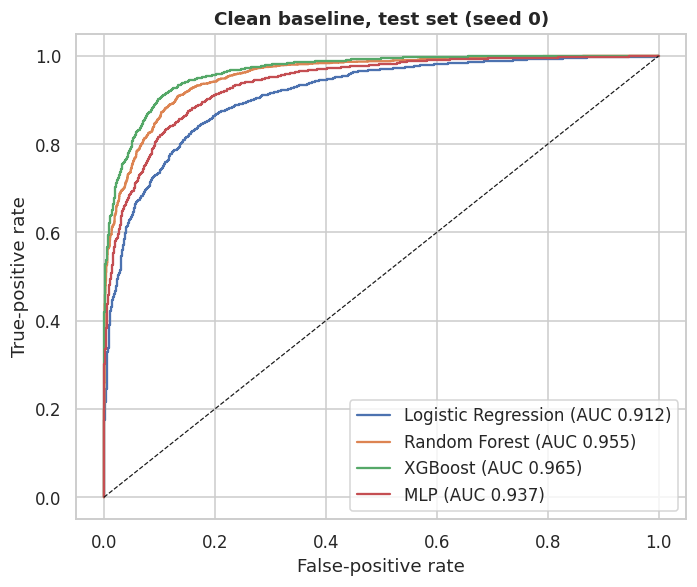

In [12]:
# ===================================================================
# Cell 13 — Clean baseline (seed 0): four models on the clean scenario
# ===================================================================
baseline_rows, baseline_probs = [], {}
for name in CFG["MODELS"]:
    bb, met = train_and_eval(clean, name)
    p = bb.predict_proba(clean.X_test)
    assert p.shape == (len(clean.X_test), 2) and 0 <= p.min() and p.max() <= 1
    baseline_probs[name] = p[:, 1]
    baseline_rows.append(dict(model=MODEL_LABELS[name], **{k: round(v, 4) for k, v in met.items()}))
baseline = pd.DataFrame(baseline_rows).set_index("model")
display(baseline[["auc_train", "auc_val", "auc_test", "acc_train", "acc_val", "acc_test",
                  "f1_train", "f1_val", "f1_test", "logloss_train", "logloss_val", "logloss_test", "fit_seconds"]])

gap = (baseline["auc_train"] - baseline["auc_test"]).rename("train-test AUC gap")
print("Train-test AUC gap (flexible models overfit more than Logistic Regression):")
print(gap.round(4).to_string())
for model, a in baseline["auc_test"].items():
    print(f"[{'PASS' if 0.80 <= a <= 0.98 else 'WARN'}] clean test AUC of {model}: {a:.4f} (expected in [0.80, 0.98])")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name in CFG["MODELS"]:
    fpr, tpr, _ = roc_curve(clean.y_test, baseline_probs[name])
    ax.plot(fpr, tpr, label=f"{MODEL_LABELS[name]} (AUC {roc_auc_score(clean.y_test, baseline_probs[name]):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="Clean baseline, test set (seed 0)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "00_clean_baseline_roc.png"), bbox_inches="tight"); plt.show()

---
# PART C — The leakage detector
**Inputs:** processed train/test arrays, labels, feature names, optional timestamps, optional row ids (evidence only) and the model as a **black box** (`predict` / `predict_proba`).
**Output per leakage type:** score ∈ [0, 1], flag, evidence; plus verdict, estimated performance inflation and every sub-signal.
Data-level signals are computed once per scenario and cached; model-level signals are recomputed per model. A fixed surrogate probe (`HistGradientBoostingClassifier`) is used wherever the detector must re-train something.

In [13]:
# ===================================================================
# PART C — THE LEAKAGE DETECTOR
# Detector interface:  LeakageDetector(model: BlackBox, X_train, y_train, X_test, y_test, feature_names,
#                                      ts_train=None, ts_test=None, row_id_train, row_id_test, seed, thresholds)
# Inputs are ONLY the processed arrays, labels, feature names, optional timestamps, optional row ids (used for
# evidence only) and the black-box model. A fixed surrogate probe (HistGradientBoosting) is used wherever the
# detector has to re-train something, because the evaluated model is a black box and cannot be cloned.
# -------------------------------------------------------------------
# Cell 14 — Detector utilities
# ===================================================================
def auc(y, p):
    y = np.asarray(y)
    return float(roc_auc_score(y, p)) if len(np.unique(y)) > 1 else float("nan")

def clip01(x):
    return np.clip(x, 0.0, 1.0)

def robust_z(v):
    v = np.asarray(v, dtype=float)
    med = np.median(v)
    mad = np.median(np.abs(v - med))
    return (v - med) / (1.4826 * mad + 1e-9)

def row_hash(X, decimals=None):
    """Hash every row (rounded, bytes -> blake2b). Identical rows hash equal. Returns a list of bytes."""
    decimals = CFG["ROUND_DECIMALS"] if decimals is None else decimals
    Xr = np.ascontiguousarray(np.round(np.asarray(X, dtype=np.float64), decimals) + 0.0)   # + 0.0 turns -0.0 into 0.0
    return [hashlib.blake2b(Xr[i].tobytes(), digest_size=8).digest() for i in range(Xr.shape[0])]

def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (float("nan"), float("nan"))
    ph = k / n
    den = 1 + z**2 / n
    centre = (ph + z**2 / (2 * n)) / den
    half = z * math.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / den
    return (max(0.0, centre - half), min(1.0, centre + half))

def binom_excess_test(k, n, base_rate):
    """One-sided exact binomial test: is the observed rate k/n larger than base_rate?  Returns the p-value."""
    if n <= 0:
        return 1.0
    base = float(np.clip(base_rate, 1e-9, 1 - 1e-9))
    return float(stats.binomtest(int(k), int(n), p=base, alternative="greater").pvalue)

def stratified_subsample(y, n, rng):
    """Indices of a class-proportional subsample of size ~n (all indices if n >= len(y))."""
    y = np.asarray(y)
    if n >= len(y):
        return np.arange(len(y))
    keep = []
    for cls in np.unique(y):
        ii = np.flatnonzero(y == cls)
        k = max(1, int(round(n * len(ii) / len(y))))
        keep.append(rng.choice(ii, size=min(k, len(ii)), replace=False))
    return np.sort(np.concatenate(keep))

def to_jsonable(o):
    """Recursively convert numpy / NaN values so that json.dumps works (NaN -> None)."""
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_jsonable(o.tolist())
    if isinstance(o, (np.floating, float)):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, (np.integer,)):
        return int(o)
    if isinstance(o, (np.bool_,)):
        return bool(o)
    return o

# ---- unit tests ----------------------------------------------------------------
_A = np.array([[1.0, 2.0], [1.0, 2.0], [3.0, 4.0], [-0.0, 5.0]])
_h = row_hash(_A)
assert _h[0] == _h[1] and _h[0] != _h[2], "identical rows must hash equal"
assert row_hash(np.array([[0.0, 1.0]]))[0] == row_hash(np.array([[-0.0, 1.0]]))[0], "-0.0 and 0.0 must hash equal"
_z = robust_z(np.r_[np.random.default_rng(0).normal(0, 1, 50), 25.0])
assert _z[-1] > 10 and np.abs(_z[:-1]).max() < 5, "an outlier must get a large robust z"
lo, hi = wilson_ci(50, 100); assert 0.40 < lo < 0.5 < hi < 0.60
assert binom_excess_test(30, 100, 0.05) < 1e-6 and binom_excess_test(5, 100, 0.05) > 0.4
_ss = stratified_subsample(np.r_[np.zeros(900), np.ones(100)], 200, np.random.default_rng(0))
assert len(_ss) == 200 and abs(np.mean(np.r_[np.zeros(900), np.ones(100)][_ss]) - 0.1) < 0.02
print("PASS: utilities unit tests (hash equality, robust z of an outlier, Wilson CI, binomial test, stratified subsample).")

PASS: utilities unit tests (hash equality, robust z of an outlier, Wilson CI, binomial test, stratified subsample).


In [14]:
# ===================================================================
# Cell 15 — Target-leakage module
#   data-level (cached): mutual information, single-feature strength, surrogate ablation
#   model-level (per model): black-box permutation importance
# NOTE: `median_income` is a strong LEGITIMATE feature (single-feature AUC ~0.85-0.9). The ablation term and
# the `a - 0.85` offset exist so that it is not flagged; cell 24 verifies this on clean data.
# ===================================================================
def _single_feature_strength(x, y, seed):
    """max(rank AUC in both directions, 3-fold CV AUC of a depth-4 decision tree)."""
    a = roc_auc_score(y, x)
    rank_auc = max(a, 1 - a)
    cv = StratifiedKFold(3, shuffle=True, random_state=seed)
    p = cross_val_predict(DecisionTreeClassifier(max_depth=4, random_state=seed), x.reshape(-1, 1), y,
                          cv=cv, method="predict_proba")[:, 1]
    return max(rank_auc, roc_auc_score(y, p))

def target_data_level(X_train, y_train, X_test, y_test, seed):
    rng = np.random.default_rng(seed)
    d = X_train.shape[1]
    idx = stratified_subsample(y_train, CFG["MI_SUBSAMPLE"], rng)
    Xs, ys = X_train[idx], y_train[idx]
    discrete = np.array([len(np.unique(Xs[:, j])) <= 10 for j in range(d)])
    mi = mutual_info_classif(Xs, ys, discrete_features=discrete, n_neighbors=3, random_state=seed)
    mi_z = robust_z(mi)
    top = np.argsort(-mi)[:min(CFG["TOP_K"], d)]

    a = np.full(d, np.nan)
    for j in top:                                             # mean of the strength on train and on test
        a[j] = 0.5 * (_single_feature_strength(Xs[:, j], ys, seed) + _single_feature_strength(X_test[:, j], y_test, seed))

    drop = np.zeros(d)                                        # surrogate ablation (3-fold CV AUC on train)
    cv = StratifiedKFold(3, shuffle=True, random_state=seed)
    mk = lambda: HistGradientBoostingClassifier(max_iter=100, random_state=seed)
    auc_all = cross_val_score(mk(), Xs, ys, cv=cv, scoring="roc_auc").mean()
    for j in top:
        keep = [k for k in range(d) if k != j]
        drop[j] = auc_all - cross_val_score(mk(), Xs[:, keep], ys, cv=cv, scoring="roc_auc").mean()
    return dict(mi=mi, mi_z=mi_z, top=top, a=a, drop=drop, auc_all=float(auc_all))

def target_model_level(bb, X_test, y_test, seed):
    """Black-box permutation importance (AUC loss) on <= PERM_ROWS test rows; returns each feature's positive share."""
    rng = np.random.default_rng(seed + 17)
    d = X_test.shape[1]
    idx = stratified_subsample(y_test, CFG["PERM_ROWS"], rng)
    Xp, yp = X_test[idx], y_test[idx]
    base = auc(yp, bb.predict_proba(Xp)[:, 1])
    imp = np.zeros(d)
    for j in range(d):
        losses = []
        for _ in range(CFG["PERM_REPEATS"]):
            Xq = Xp.copy()
            Xq[:, j] = rng.permutation(Xq[:, j])
            losses.append(base - auc(yp, bb.predict_proba(Xq)[:, 1]))
        imp[j] = float(np.mean(losses))
    pos = np.clip(imp, 0, None)
    share = pos / pos.sum() if pos.sum() > 0 else np.zeros(d)
    return dict(perm_importance=imp, share=share)

def target_scores(dl, ml, feature_names):
    z, a, drop, share = dl["mi_z"], np.nan_to_num(dl["a"], nan=0.0), dl["drop"], ml["share"]
    s_mi = clip01(np.log10(np.maximum(z, 1.0)) / 2.0)
    s_auc = clip01((a - 0.85) / 0.15)
    s_abl = clip01(drop / 0.05)
    s_perm = clip01((share - 0.3) / 0.5)
    f = 0.35 * s_mi + 0.30 * s_auc + 0.20 * s_abl + 0.15 * s_perm
    table = [dict(feature=feature_names[j], mi=float(dl["mi"][j]), mi_z=float(z[j]),
                  single_feature_strength=(None if np.isnan(dl["a"][j]) else float(dl["a"][j])),
                  ablation_drop=float(drop[j]), perm_share=float(share[j]),
                  s_mi=float(s_mi[j]), s_auc=float(s_auc[j]), s_abl=float(s_abl[j]), s_perm=float(s_perm[j]), f=float(f[j]))
             for j in range(len(feature_names))]
    sub = dict(mi_z_max=float(np.max(z)), single_feature_auc_max=float(np.max(a)), ablation_drop_max=float(np.max(drop)),
               perm_share_max=float(np.max(share)), s_mi_max=float(s_mi.max()), s_auc_max=float(s_auc.max()),
               s_abl_max=float(s_abl.max()), s_perm_max=float(s_perm.max()))
    return float(f.max()), f, table, sub

print("Target module ready: MI z-score + single-feature strength + ablation (data-level), permutation share (model-level).")

Target module ready: MI z-score + single-feature strength + ablation (data-level), permutation share (model-level).


In [15]:
# ===================================================================
# Cell 16 — Contamination module
#   data-level (cached): exact-duplicate overlap + near-duplicate nearest-neighbour excess, each against a
#                        leave-one-out within-train baseline;  model-level: memorisation gap on matched test rows
# ===================================================================
def contamination_data_level(X_train, X_test, row_id_train, row_id_test, seed):
    rng = np.random.default_rng(seed + 31)
    n_tr, n_te = len(X_train), len(X_test)

    # ---- 1. exact overlap (hash of the rounded rows) -------------------------------------
    h_tr, h_te = row_hash(X_train), row_hash(X_test)
    first_pos = {}
    for i, h in enumerate(h_tr):
        first_pos.setdefault(h, i)
    exact_mask = np.array([h in first_pos for h in h_te])
    partner = np.array([first_pos.get(h, -1) for h in h_te])
    exact_rate = float(exact_mask.mean())
    # Baseline = LEAVE-ONE-OUT within train: a sampled train row is compared with ALL OTHER train rows.
    # (Holding rows out and fitting on the remainder would give the baseline a ~33% smaller reference set than the
    #  test queries have, which makes honest test rows look spuriously "closer" and inflates the clean-data score.)
    n_hold = min(CFG["NN_HOLDOUT"], n_tr // 3)
    hold = rng.choice(n_tr, size=n_hold, replace=False)
    h_count = {}
    for h in h_tr:
        h_count[h] = h_count.get(h, 0) + 1
    b_exact = float(np.mean([h_count[h_tr[i]] > 1 for i in hold]))      # does the row have an identical twin elsewhere in train?
    excess_exact = max(0.0, exact_rate - b_exact)
    p_exact = binom_excess_test(int(exact_mask.sum()), n_te, b_exact)
    if p_exact >= 0.01:
        excess_exact = 0.0

    # ---- 2. near-duplicates (kd-tree nearest neighbour on the FULL train) -------------------
    nq = min(CFG["NN_QUERY"], n_te)
    q_idx = rng.choice(n_te, size=nq, replace=False)
    nn_full = NearestNeighbors(n_neighbors=1, algorithm="kd_tree").fit(X_train)
    d_test, nn_idx = nn_full.kneighbors(X_test[q_idx])
    d_test, nn_idx = d_test[:, 0], nn_idx[:, 0]
    d_base = nn_full.kneighbors(X_train[hold], n_neighbors=2)[0][:, 1]       # 2nd neighbour = nearest OTHER train row
    eps = max(float(np.quantile(d_base, 0.05)), 1e-6)
    o = float(np.mean(d_test <= eps))
    b = float(np.mean(d_base <= eps))
    excess_nn = max(0.0, (o - b) / (1 - b)) if b < 1 else 0.0
    p_nn = binom_excess_test(int(round(o * nq)), nq, b)
    if p_nn >= 0.01:
        excess_nn = 0.0

    s_dup = float(clip01(excess_exact / 0.02))
    s_nn = float(clip01(excess_nn / 0.05))

    # ---- evidence + the set of matched test rows (only if a signal is significant) ----------
    sig_any = excess_exact > 0 or excess_nn > 0
    matched = np.zeros(n_te, dtype=bool)
    if excess_exact > 0:
        matched |= exact_mask
    if excess_nn > 0:
        matched[q_idx[d_test <= eps]] = True
    exact_rows = np.flatnonzero(exact_mask) if sig_any else np.array([], dtype=int)
    near_sel = d_test <= eps
    pos_q = {int(r): i for i, r in enumerate(q_idx)}
    near_rows = np.array([r for r in q_idx[near_sel] if not exact_mask[r]], dtype=int) if excess_nn > 0 else np.array([], dtype=int)
    near_partner = np.array([nn_idx[pos_q[int(r)]] for r in near_rows], dtype=int) if len(near_rows) else np.array([], dtype=int)
    rid_tr, rid_te = np.asarray(row_id_train), np.asarray(row_id_test)
    evidence = dict(
        n_exact=int(len(exact_rows)), n_near=int(len(near_rows)),
        dup_test_row_ids=rid_te[np.concatenate([exact_rows, near_rows]).astype(int)].tolist(),
        dup_test_row_ids_exact=rid_te[exact_rows].tolist(),
        dup_test_row_ids_near=rid_te[near_rows].tolist(),
        dup_train_row_ids=np.concatenate([rid_tr[partner[exact_rows]] if len(exact_rows) else np.array([], int),
                                          rid_tr[near_partner] if len(near_partner) else np.array([], int)]).astype(int).tolist(),
        near_eps=eps)
    return dict(exact_rate=exact_rate, base_exact=b_exact, excess_exact=excess_exact, p_exact=p_exact,
                nn_eps=eps, nn_obs=o, nn_base=b, excess_nn=excess_nn, p_nn=p_nn,
                s_dup=s_dup, s_nn=s_nn, matched_mask=matched, evidence=evidence,
                exact_mask=exact_mask, exact_partner=partner)

def contamination_model_level(bb, X_test, y_test, dl, p_test=None):
    """Memorisation gap: black-box AUC on matched test rows minus AUC on unmatched rows (>= 30 matched rows needed)."""
    m = dl["matched_mask"]
    gap = float("nan")
    if m.sum() >= 30 and (~m).sum() >= 30 and len(np.unique(y_test[m])) > 1 and len(np.unique(y_test[~m])) > 1:
        p = bb.predict_proba(X_test)[:, 1] if p_test is None else p_test
        gap = auc(y_test[m], p[m]) - auc(y_test[~m], p[~m])
    s_mem = float(clip01(gap / 0.2)) if np.isfinite(gap) else 0.0
    return dict(mem_gap=gap, s_mem=s_mem, n_matched=int(m.sum()))

def contamination_score(dl, ml):
    return float(0.8 * max(dl["s_dup"], dl["s_nn"]) + 0.2 * ml["s_mem"])

print("Contamination module ready: exact hash overlap + kd-tree near-duplicate excess (both vs. a within-train baseline).")

Contamination module ready: exact hash overlap + kd-tree near-duplicate excess (both vs. a within-train baseline).


In [16]:
# ===================================================================
# Cell 17 — Temporal-leakage module
# Abstains when no timestamps are given (the case for every real run on this dataset). The full logic is
# implemented anyway and self-tested on a SYNTHETIC dataset below (not part of the reported results).
# ===================================================================
def _ts_to_float(ts):
    ts = pd.Series(ts)
    if np.issubdtype(ts.dtype, np.datetime64):
        return ts.astype("int64").to_numpy(dtype=float)
    return ts.to_numpy(dtype=float)

def temporal_module(X_train, y_train, X_test, y_test, ts_train=None, ts_test=None, exclude_train_pos=None, seed=0):
    if ts_train is None or ts_test is None:
        return dict(score=float("nan"), evidence={"abstained": "no timestamp"}, signals={})
    t_tr, t_te = _ts_to_float(ts_train), _ts_to_float(ts_test)
    keep = np.ones(len(t_tr), dtype=bool)
    if exclude_train_pos is not None and len(exclude_train_pos):       # de-duplicate first (cell 16 matches)
        keep[np.asarray(exclude_train_pos, dtype=int)] = False
    t_lo, t_hi = float(np.min(t_te)), float(np.max(t_te))
    overlap_frac = float(np.mean(t_tr[keep] >= t_lo))                  # train rows at/after the start of the test period
    future_frac = float(np.mean(t_tr[keep] > t_hi))                    # train rows strictly after the test period
    suggested_cut = t_lo
    # time-ordered re-split with the surrogate: same sizes, but strictly chronological
    mk = lambda: HistGradientBoostingClassifier(max_iter=100, random_state=seed)
    a_given = auc(y_test, mk().fit(X_train[keep], y_train[keep]).predict_proba(X_test)[:, 1])
    Xa, ya, ta = np.vstack([X_train, X_test]), np.r_[y_train, y_test], np.r_[t_tr, t_te]
    order = np.argsort(ta, kind="stable")
    n_tr = len(X_train)
    tr_i, te_i = order[:n_tr], order[n_tr:]
    a_chrono = auc(ya[te_i], mk().fit(Xa[tr_i], ya[tr_i]).predict_proba(Xa[te_i])[:, 1])
    delta = a_given - a_chrono
    score = 0.7 * float(clip01(overlap_frac / 0.05)) + 0.3 * float(clip01(delta / 0.05))
    return dict(score=score,
                evidence=dict(overlap_frac=overlap_frac, future_frac=future_frac, suggested_cut=suggested_cut,
                              auc_given_split=a_given, auc_chronological=a_chrono, delta=delta),
                signals=dict(overlap_frac=overlap_frac, future_frac=future_frac, temporal_delta=delta))

# ---- SELF-TEST on synthetic timestamps (verifies the module for datasets that DO have time) --------------
def _synthetic_time_data(n=6000, seed=0):
    r = np.random.default_rng(seed)
    t = np.sort(r.uniform(0, 1, n))
    X = r.normal(size=(n, 4))
    w = np.stack([np.cos(3 * t), np.sin(3 * t), 0.5 * np.ones(n), -0.5 * np.ones(n)], axis=1)   # concept drift over time
    y = ((X * w).sum(1) + 0.3 * r.normal(size=n) > 0).astype(int)
    return X, y, t

_X, _y, _t = _synthetic_time_data()
_past = np.flatnonzero(_t < 0.6); _test = np.flatnonzero((_t >= 0.6) & (_t < 0.8)); _future = np.flatnonzero(_t >= 0.8)
_r = np.random.default_rng(1)
ok_split = _past                                                                # correct chronological split
leaky = np.r_[_past, _r.choice(_future, size=int(0.25 * len(_past)), replace=False)]   # ~20% of train after the test period
res_ok = temporal_module(_X[ok_split], _y[ok_split], _X[_test], _y[_test], _t[ok_split], _t[_test])
res_leak = temporal_module(_X[leaky], _y[leaky], _X[_test], _y[_test], _t[leaky], _t[_test])
res_none = temporal_module(_X[ok_split], _y[ok_split], _X[_test], _y[_test])
print(f"correct chronological split : score = {res_ok['score']:.3f}  overlap_frac = {res_ok['evidence']['overlap_frac']:.3f}  -> {'PASS (no flag)' if res_ok['score'] < 0.5 else 'FAIL'}")
print(f"20% of train after test     : score = {res_leak['score']:.3f}  overlap_frac = {res_leak['evidence']['overlap_frac']:.3f}  -> {'PASS (flag)' if res_leak['score'] >= 0.5 else 'FAIL'}")
print(f"no timestamp (this dataset) : score = {res_none['score']}  evidence = {res_none['evidence']}  -> {'PASS (abstains)' if np.isnan(res_none['score']) else 'FAIL'}")
assert res_ok["score"] < 0.5 <= res_leak["score"] and np.isnan(res_none["score"]), "temporal module self-test failed"
del _X, _y, _t, _past, _test, _future, _r, ok_split, leaky

correct chronological split : score = 0.000  overlap_frac = 0.000  -> PASS (no flag)
20% of train after test     : score = 1.000  overlap_frac = 0.200  -> PASS (flag)
no timestamp (this dataset) : score = nan  evidence = {'abstained': 'no timestamp'}  -> PASS (abstains)


In [17]:
# ===================================================================
# Cell 18 — Preprocessing-leakage module (works on the processed arrays only, exact fingerprints)
#   A column is "train-consistent" if its statistics look like they were fitted on train only, and
#   "pooled-consistent" if they look like they were fitted on train+test. A score is the share of
#   pooled-consistent columns among all columns that are consistent with ANY story (columns that fit neither
#   story, e.g. a naturally capped column, say nothing about the fit scope and are ignored).
# ===================================================================
def _ratio(n_pool, n_train):
    return float(n_pool / (n_pool + n_train)) if (n_pool + n_train) > 0 else 0.0

def preprocessing_module(X_train, X_test, feature_names):
    tol = CFG["FP_TOL"]
    Xp = np.vstack([X_train, X_test])
    d = X_train.shape[1]
    nuniq = np.array([len(np.unique(Xp[:, j])) for j in range(d)])
    ev = dict(scaler={}, imputation={}, encoding={})

    # 1. scaler fingerprint (> 20 distinct values; frequency-encoded columns have <= 10)
    n_pool = n_train = 0
    for j in np.flatnonzero(nuniq > 20):
        tr, po = X_train[:, j], Xp[:, j]
        std_tr = abs(tr.mean()) < tol and abs(tr.std() - 1) < tol
        mm_tr = abs(tr.min()) < tol and abs(tr.max() - 1) < tol
        std_po = abs(po.mean()) < tol and abs(po.std() - 1) < tol
        mm_po = abs(po.min()) < tol and abs(po.max() - 1) < tol
        train_cons = std_tr or mm_tr
        pooled_cons = (std_po or mm_po) and not train_cons
        n_train += int(train_cons); n_pool += int(pooled_cons)
        ev["scaler"][feature_names[j]] = ("train-consistent" if train_cons else "POOLED-consistent" if pooled_cons else "neither")
    s_scale = _ratio(n_pool, n_train)

    # 2. imputation fingerprint: a spike (modal value with frequency in [1%, 80%]) equal to a column mean
    n_pool = n_train = 0
    for j in range(d):
        vals, cnt = np.unique(X_train[:, j], return_counts=True)
        freq = cnt.max() / len(X_train)
        if not (0.01 <= freq <= 0.80):
            continue
        v = vals[cnt.argmax()]
        m_tr = X_train[X_train[:, j] != v, j].mean()
        m_po = Xp[Xp[:, j] != v, j].mean()
        train_cons = abs(v - m_tr) < tol
        pooled_cons = abs(v - m_po) < tol and abs(v - m_tr) > 10 * tol
        n_train += int(train_cons); n_pool += int(pooled_cons)
        ev["imputation"][feature_names[j]] = dict(spike_share=float(freq),
            verdict=("train-consistent" if train_cons else "POOLED-consistent" if pooled_cons else "neither"))
    s_imp = _ratio(n_pool, n_train)

    # 3. frequency-encoding fingerprint: unscaled columns with <= 10 distinct values in (0, 1]
    n_pool = n_train = 0
    for j in np.flatnonzero(nuniq <= 10):
        po_vals = np.unique(Xp[:, j])
        vals = po_vals[po_vals != 0.0]
        if len(vals) == 0 or vals.min() <= 0 or vals.max() > 1:
            continue
        tr_ok = all(abs(v - np.mean(X_train[:, j] == v)) < tol for v in vals)
        po_ok = all(abs(v - np.mean(Xp[:, j] == v)) < tol for v in vals)
        train_cons, pooled_cons = tr_ok, po_ok and not tr_ok
        n_train += int(train_cons); n_pool += int(pooled_cons)
        ev["encoding"][feature_names[j]] = ("train-consistent" if train_cons else "POOLED-consistent" if pooled_cons else "neither")
    s_enc = _ratio(n_pool, n_train)

    score = float(max(s_scale, s_imp, s_enc))
    if not (ev["scaler"] or ev["imputation"] or ev["encoding"]):
        ev["note"] = "no fingerprintable column"
    return dict(score=score, s_scale=s_scale, s_imp=s_imp, s_enc=s_enc, evidence=ev)

# ---- checks on the real scenarios (seed 0): clean -> 0, prep_L -> scale, prep_M adds imputation, prep_H adds encoding
_exp = {"clean": (0, 0, 0), "prep_L": (1, 0, 0), "prep_M": (1, 1, 0)}
if HAS_CATEGORICAL:
    _exp["prep_H"] = (1, 1, 1)
for _sid, (e_sc, e_im, e_en) in _exp.items():
    _s = build_scenario(0, _sid)
    _r = preprocessing_module(_s.X_train, _s.X_test, _s.feature_names)
    _ok = abs(_r["s_scale"] - e_sc) < 1e-9 and abs(_r["s_imp"] - e_im) < 1e-9 and abs(_r["s_enc"] - e_en) < 1e-9
    print(f"[{'PASS' if _ok else 'FAIL'}] {_sid:7s} s_scale={_r['s_scale']:.2f} s_imp={_r['s_imp']:.2f} s_enc={_r['s_enc']:.2f}  (expected {e_sc},{e_im},{e_en})")
    assert _ok, f"preprocessing fingerprint check failed for {_sid}"
del _s, _r

[PASS] clean   s_scale=0.00 s_imp=0.00 s_enc=0.00  (expected 0,0,0)
[PASS] prep_L  s_scale=1.00 s_imp=0.00 s_enc=0.00  (expected 1,0,0)
[PASS] prep_M  s_scale=1.00 s_imp=1.00 s_enc=0.00  (expected 1,1,0)


In [18]:
# ===================================================================
# Cell 19 — Adversarial validation (supporting signal only: weight 0 in every score)
# ===================================================================
TIME_PROXY_TOKENS = {"time", "date", "year", "month", "week", "day", "timestamp", "period"}

def adversarial_validation(X_train, X_test, feature_names, seed):
    """Train rows = 0, test rows = 1; 3-fold out-of-fold AUC of a small random forest (~0.5 for a random split)."""
    rng = np.random.default_rng(seed + 53)
    drop = [j for j, nm in enumerate(feature_names) if set(str(nm).lower().split("_")) & TIME_PROXY_TOKENS]
    keep = [j for j in range(X_train.shape[1]) if j not in drop]      # no time-proxy columns here -> nothing removed
    n_tot = len(X_train) + len(X_test)
    frac = min(1.0, CFG["ADV_SUBSAMPLE"] / n_tot)
    i_tr = rng.choice(len(X_train), size=int(len(X_train) * frac), replace=False)
    i_te = rng.choice(len(X_test), size=int(len(X_test) * frac), replace=False)
    X = np.vstack([X_train[i_tr][:, keep], X_test[i_te][:, keep]])
    y = np.r_[np.zeros(len(i_tr)), np.ones(len(i_te))].astype(int)
    rf = RandomForestClassifier(n_estimators=100, max_depth=8, n_jobs=-1, random_state=seed)
    oof = cross_val_predict(rf, X, y, cv=StratifiedKFold(3, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    adv_auc = float(roc_auc_score(y, oof))
    imp = rf.fit(X, y).feature_importances_
    top = np.argsort(-imp)[:5]
    return dict(adv_auc=adv_auc, top_features=[(feature_names[keep[j]], float(imp[j])) for j in top],
                removed_time_proxies=[feature_names[j] for j in drop])

_s = build_scenario(0, "clean")
_adv = adversarial_validation(_s.X_train, _s.X_test, _s.feature_names, 0)
print(f"clean, seed 0: adversarial AUC = {_adv['adv_auc']:.3f} (about 0.5 expected for a random split) | removed time proxies: {_adv['removed_time_proxies'] or 'none'}")
print("top-5 importances:", [(n, round(v, 3)) for n, v in _adv["top_features"]])
del _s, _adv

clean, seed 0: adversarial AUC = 0.501 (about 0.5 expected for a random split) | removed time proxies: none
top-5 importances: [('median_income', 0.143), ('rooms', 0.143), ('households_or_occupancy', 0.14), ('bedrooms', 0.131), ('population', 0.13)]


In [19]:
# ===================================================================
# Cell 20 — Model-level signals (stored in `signals`, evaluated in cell 29, never used alone to flag)
# ===================================================================
def model_level_signals(bb, X_train, y_train, X_test, y_test, p_test=None):
    p_tr = bb.predict_proba(X_train)
    p_te = bb.predict_proba(X_test) if p_test is None else np.column_stack([1 - p_test, p_test])
    return dict(gap_auc=auc(y_train, p_tr[:, 1]) - auc(y_test, p_te[:, 1]),
                gap_conf=float(p_tr.max(axis=1).mean() - p_te.max(axis=1).mean()),
                auc_train_bb=auc(y_train, p_tr[:, 1]), auc_test_bb=auc(y_test, p_te[:, 1]))

print("Model-level signals: gap_auc = AUC_train - AUC_test and gap_conf = mean(max proba) train - test.")

Model-level signals: gap_auc = AUC_train - AUC_test and gap_conf = mean(max proba) train - test.


In [20]:
# ===================================================================
# Cell 21 — Remediation and performance-inflation estimate
#   AUC_given     = black-box AUC on the test set as given
#   target        : replace each flagged suspect column of the test matrix by a within-test permutation of itself
#   contamination : drop the test rows matched as duplicates
#   est = AUC_given - AUC_after_remediation   (clipped at 0)
#   preprocessing : not estimated (documented blind spot, contribution 0);  temporal : not applicable
# ===================================================================
def estimate_inflation(bb, X_test, y_test, p_given, flags, suspect_idx, matched_mask, seed):
    rng = np.random.default_rng(seed + 71)
    auc_given = auc(y_test, p_given)
    est = {"target": 0.0, "contamination": 0.0, "temporal": None, "preprocessing": 0.0}

    def _permute(Xm):
        Xm = Xm.copy()
        for j in suspect_idx:
            Xm[:, j] = rng.permutation(Xm[:, j])
        return Xm

    do_t = bool(flags["target"]) and len(suspect_idx) > 0
    do_c = bool(flags["contamination"]) and int(matched_mask.sum()) > 0
    keep = ~matched_mask if do_c else np.ones(len(y_test), dtype=bool)
    valid = lambda m: len(np.unique(y_test[m])) > 1
    if do_t:
        est["target"] = max(0.0, auc_given - auc(y_test, bb.predict_proba(_permute(X_test))[:, 1]))
    if do_c and valid(keep):
        est["contamination"] = max(0.0, auc_given - auc(y_test[keep], p_given[keep]))
    total = 0.0
    if (do_t or do_c) and valid(keep):                      # both remediations applied jointly (no double counting)
        Xr = _permute(X_test[keep]) if do_t else X_test[keep]
        total = max(0.0, auc_given - auc(y_test[keep], bb.predict_proba(Xr)[:, 1]))
    return dict(auc_given=auc_given, est_inflation=float(total), est_by_type=est)

print("Inflation estimator ready (target: permute suspects; contamination: drop matched rows; others: 0 / n.a.).")

Inflation estimator ready (target: permute suspects; contamination: drop matched rows; others: 0 / n.a.).


In [21]:
# ===================================================================
# Cell 22 — Aggregator: LeakageDetector (data-level cache per scenario, model-level per model)
# ===================================================================
def compute_data_level(X_train, y_train, X_test, y_test, feature_names, ts_train=None, ts_test=None,
                       row_id_train=None, row_id_test=None, seed=0):
    """All signals that depend on the DATA only. Computed once per scenario and reused for every model."""
    row_id_train = np.arange(len(X_train)) if row_id_train is None else row_id_train
    row_id_test = np.arange(len(X_test)) + 10**9 if row_id_test is None else row_id_test
    c, tm = {}, {}
    t = time.time(); c["contam"] = contamination_data_level(X_train, X_test, row_id_train, row_id_test, seed); tm["contamination"] = time.time() - t
    t = time.time(); c["target"] = target_data_level(X_train, y_train, X_test, y_test, seed); tm["target"] = time.time() - t
    t = time.time(); c["prep"] = preprocessing_module(X_train, X_test, feature_names); tm["preprocessing"] = time.time() - t
    t = time.time(); c["adv"] = adversarial_validation(X_train, X_test, feature_names, seed); tm["adversarial"] = time.time() - t
    t = time.time()
    excl = c["contam"]["exact_partner"][c["contam"]["exact_mask"]] if c["contam"]["exact_mask"].any() else []
    c["temporal"] = temporal_module(X_train, y_train, X_test, y_test, ts_train, ts_test, exclude_train_pos=excl, seed=seed)
    tm["temporal"] = time.time() - t
    c["timings"] = tm
    return c

class LeakageDetector:
    def __init__(self, model, X_train, y_train, X_test, y_test, feature_names, ts_train=None, ts_test=None,
                 row_id_train=None, row_id_test=None, seed=0, thresholds=None, cache=None):
        self.model = model if isinstance(model, BlackBox) else BlackBox(model)
        self.X_train, self.y_train, self.X_test, self.y_test = X_train, y_train, X_test, y_test
        self.names = list(feature_names)
        self.seed = seed
        self.thr = dict(CFG["THRESH"] if thresholds is None else thresholds)
        self.row_id_train, self.row_id_test = row_id_train, row_id_test
        self.cache = cache if cache is not None else compute_data_level(
            X_train, y_train, X_test, y_test, feature_names, ts_train, ts_test, row_id_train, row_id_test, seed)

    def run(self, model=None):
        bb = self.model if model is None else (model if isinstance(model, BlackBox) else BlackBox(model))
        C, tm = self.cache, {}
        t0 = time.time()
        p_test = bb.predict_proba(self.X_test)[:, 1]

        t = time.time(); ml_t = target_model_level(bb, self.X_test, self.y_test, self.seed); tm["target_model"] = time.time() - t
        sc_t, f_t, table, sub_t = target_scores(C["target"], ml_t, self.names)
        t = time.time(); ml_c = contamination_model_level(bb, self.X_test, self.y_test, C["contam"], p_test); tm["contamination_model"] = time.time() - t
        sc_c = contamination_score(C["contam"], ml_c)
        sc_p = C["prep"]["score"]
        tmp = C["temporal"]
        t = time.time(); gaps = model_level_signals(bb, self.X_train, self.y_train, self.X_test, self.y_test, p_test); tm["gaps"] = time.time() - t

        scores = dict(target=sc_t, contamination=sc_c, temporal=float("nan"), preprocessing=sc_p)
        flags = {k: bool(np.isfinite(v) and v >= self.thr[k]) for k, v in scores.items()}       # temporal: NaN -> False
        order = np.argsort(-f_t)
        suspect_idx = [int(j) for j in order if f_t[j] >= self.thr["target"]]
        t = time.time()
        infl = estimate_inflation(bb, self.X_test, self.y_test, p_test, flags, suspect_idx, C["contam"]["matched_mask"], self.seed)
        tm["inflation"] = time.time() - t

        cd, cev = C["contam"], C["contam"]["evidence"]
        signals = dict(sub_t, exact_excess=cd["excess_exact"], nn_excess=cd["excess_nn"], s_dup=cd["s_dup"], s_nn=cd["s_nn"],
                       mem_gap=ml_c["mem_gap"], s_mem=ml_c["s_mem"], n_matched=ml_c["n_matched"], near_eps=cd["nn_eps"],
                       base_exact=cd["base_exact"], base_nn=cd["nn_base"],
                       s_scale=C["prep"]["s_scale"], s_imp=C["prep"]["s_imp"], s_enc=C["prep"]["s_enc"],
                       adv_auc=C["adv"]["adv_auc"], gap_auc=gaps["gap_auc"], gap_conf=gaps["gap_conf"],
                       auc_given=infl["auc_given"], n_blackbox_calls=bb.n_calls)
        report = {
            "target": dict(score=sc_t, flag=flags["target"], evidence=dict(
                suspect_features=[self.names[j] for j in suspect_idx],
                ranked_features=[self.names[j] for j in order[:5]],
                per_feature=table)),
            "contamination": dict(score=sc_c, flag=flags["contamination"], evidence=cev),
            "temporal": dict(score=float("nan"), flag=False, evidence=tmp["evidence"]),
            "preprocessing": dict(score=sc_p, flag=flags["preprocessing"], evidence=C["prep"]["evidence"]),
            "verdict": "leaky" if any(flags.values()) else "clean",
            "est_inflation": infl["est_inflation"],
            "est_inflation_by_type": infl["est_by_type"],
            "signals": signals,
            "adversarial_top_features": C["adv"]["top_features"],
            "timings": dict(C["timings"], **tm, total_model_level=time.time() - t0),
            "_suspect_idx": suspect_idx,
        }
        # contract: all keys present, no NaN score except the temporal abstention
        assert all(k in report for k in ("target", "contamination", "temporal", "preprocessing", "verdict", "est_inflation", "est_inflation_by_type", "signals"))
        assert all(np.isfinite(report[k]["score"]) for k in ("target", "contamination", "preprocessing")), "NaN score"
        return report

def detector_for(scn, bb, cache=None, thresholds=None):
    """Build a detector from a ScenarioData: ONLY arrays, labels, names, timestamps (None), row ids and the black box."""
    return LeakageDetector(bb, scn.X_train, scn.y_train, scn.X_test, scn.y_test, scn.feature_names,
                           scn.ts_train, scn.ts_test, scn.row_id_train, scn.row_id_test, scn.seed, thresholds, cache)

print("LeakageDetector ready. Data-level signals are cached per scenario; model-level signals are recomputed per model.")

LeakageDetector ready. Data-level signals are cached per scenario; model-level signals are recomputed per model.


In [22]:
# ===================================================================
# Cell 23 — Detector smoke test (seed 0, XGBoost)
# ===================================================================
smoke_ids = ["clean", "target_H", "contam_H", "prep_H" if HAS_CATEGORICAL else "prep_M"]
smoke_rows, smoke_reports = [], {}
for sid in smoke_ids:
    scn = build_scenario(0, sid)
    bb, met = train_and_eval(scn, "xgb")
    t = time.time(); det = detector_for(scn, bb); rep = det.run(); dt = time.time() - t
    smoke_reports[sid] = rep
    smoke_rows.append(dict(scenario=sid, test_auc=round(met["auc_test"], 4),
                           score_target=round(rep["target"]["score"], 3), score_contam=round(rep["contamination"]["score"], 3),
                           score_prep=round(rep["preprocessing"]["score"], 3), temporal=("abstained" if np.isnan(rep["temporal"]["score"]) else rep["temporal"]["score"]),
                           flags=[k for k in CFG["EVALUATED_TYPES"] if rep[k]["flag"]], verdict=rep["verdict"],
                           est_inflation=round(rep["est_inflation"], 4), seconds=round(dt, 1)))
display(pd.DataFrame(smoke_rows))
for sid, rep in smoke_reports.items():
    print(f"{sid:9s} suspects: {rep['target']['evidence']['suspect_features'] or '-'} | top-5 by f: {rep['target']['evidence']['ranked_features']}"
          f" | contamination: {rep['contamination']['evidence']['n_exact']} exact + {rep['contamination']['evidence']['n_near']} near")

expected = {"clean": None, "target_H": "target", "contam_H": "contamination", "prep_H": "preprocessing", "prep_M": "preprocessing"}
for sid, rep in smoke_reports.items():
    sc = {k: rep[k]["score"] for k in CFG["EVALUATED_TYPES"]}
    exp = expected[sid]
    if exp is None:
        print(f"[{'PASS' if rep['verdict'] == 'clean' else 'WARN'}] clean: no flag expected -> verdict = {rep['verdict']}")
    else:
        top = max(sc, key=sc.get)
        print(f"[{'PASS' if top == exp and rep[exp]['flag'] else 'WARN'}] {sid}: injected type '{exp}' should score highest and be flagged -> top = {top}, flagged = {rep[exp]['flag']}")
print(f"[{'PASS' if all(np.isnan(r['temporal']['score']) and r['temporal']['evidence'].get('abstained') for r in smoke_reports.values()) else 'FAIL'}] temporal module abstains ('no timestamp')")
print("Soft checks only: thresholds are calibrated next (cell 24).")

,scenario,test_auc,score_target,score_contam,score_prep,temporal,flags,verdict,est_inflation,seconds
0,clean,0.9646,0.209,0.000,0.0,abstained,[],clean,0.0000,16.2
1,target_H,1.0000,0.772,0.000,0.0,abstained,[target],leaky,0.2762,18.5
2,contam_H,0.9691,0.210,0.827,0.0,abstained,[contamination],leaky,0.0064,16.8
3,prep_M,0.9643,0.210,0.000,1.0,abstained,[preprocessing],leaky,0.0000,16.1


clean     suspects: - | top-5 by f: ['longitude', 'latitude', 'median_income', 'households_or_occupancy', 'rooms'] | contamination: 0 exact + 0 near
target_H  suspects: ['leak_feat'] | top-5 by f: ['leak_feat', 'median_income', 'longitude', 'latitude', 'households_or_occupancy'] | contamination: 0 exact + 0 near
contam_H  suspects: - | top-5 by f: ['longitude', 'latitude', 'median_income', 'households_or_occupancy', 'rooms'] | contamination: 413 exact + 542 near
prep_M    suspects: - | top-5 by f: ['longitude', 'latitude', 'median_income', 'households_or_occupancy', 'rooms'] | contamination: 0 exact + 0 near
[PASS] clean: no flag expected -> verdict = clean
[PASS] target_H: injected type 'target' should score highest and be flagged -> top = target, flagged = True
[PASS] contam_H: injected type 'contamination' should score highest and be flagged -> top = contamination, flagged = True
[PASS] prep_M: injected type 'preprocessing' should score highest and be flagged -> top = preprocessing,

In [23]:
# ===================================================================
# Cell 24 — Threshold calibration on CAL_SEEDS only, then FROZEN
#   For each evaluated type: if q95 of the CLEAN scores >= THRESH[type], set THRESH[type] = min(0.9, q95 + 0.05).
#   Thresholds are never lowered. target_M, contam_M, prep_M are run for context only (printed, not tuned).
# ===================================================================
CAL_FILE = os.path.join(RESULTS_DIR, "thresholds.json")
CAL_SIGNATURE = dict(quick=CFG["QUICK_MODE"], cal_seeds=CFG["CAL_SEEDS"], schema=SCHEMA, models=CFG["MODELS"],
                     n_rows=int(len(data)))
CONTEXT_SCENARIOS = [s for s in ("target_M", "contam_M", "prep_M") if s in ACTIVE_SCENARIOS]

loaded = None
if CFG["RESUME"] and os.path.exists(CAL_FILE):
    with open(CAL_FILE) as fh:
        saved = json.load(fh)
    if saved.get("signature") == CAL_SIGNATURE:
        loaded = saved
        print("Re-using calibrated thresholds from", CAL_FILE, "(same configuration).")

if loaded is not None:
    THRESH_FROZEN = {k: float(v) for k, v in loaded["thresholds"].items()}
    cal_df = pd.DataFrame(loaded.get("calibration_scores", []))
else:
    cal_records, median_income_f = [], []
    bar = tqdm(total=len(CFG["CAL_SEEDS"]) * (1 + len(CONTEXT_SCENARIOS)), desc="calibration")
    for seed in CFG["CAL_SEEDS"]:
        for sid in ["clean"] + CONTEXT_SCENARIOS:
            scn = build_scenario(seed, sid)
            cache = compute_data_level(scn.X_train, scn.y_train, scn.X_test, scn.y_test, scn.feature_names,
                                       scn.ts_train, scn.ts_test, scn.row_id_train, scn.row_id_test, seed)
            for name in CFG["MODELS"]:
                bb, met = train_and_eval(scn, name)
                rep = detector_for(scn, bb, cache=cache).run()
                cal_records.append(dict(seed=seed, scenario=sid, model=name, auc_test=met["auc_test"],
                                        **{f"score_{k}": rep[k]["score"] for k in CFG["EVALUATED_TYPES"]}))
                if sid == "clean":
                    row = [r for r in rep["target"]["evidence"]["per_feature"] if r["feature"] == "median_income"]
                    if row:
                        median_income_f.append(row[0]["f"])
            bar.update(1); gc.collect()
    bar.close()
    cal_df = pd.DataFrame(cal_records)

    THRESH_FROZEN = dict(CFG["THRESH"])
    clean_cal = cal_df[cal_df.scenario == "clean"]
    print("\nCLEAN scores on calibration seeds (q95 decides the threshold):")
    for t in CFG["EVALUATED_TYPES"]:
        q95 = float(np.quantile(clean_cal[f"score_{t}"], 0.95))
        old = THRESH_FROZEN[t]
        if q95 >= old:
            THRESH_FROZEN[t] = float(min(0.9, q95 + 0.05))
        print(f"  {t:14s} clean: max={clean_cal[f'score_{t}'].max():.3f}  q95={q95:.3f}  threshold {old:.2f} -> {THRESH_FROZEN[t]:.2f}")
    # median_income is a legitimate strong feature: it must not be flagged on clean data
    if median_income_f:
        worst = max(median_income_f)
        ok = worst < THRESH_FROZEN["target"]
        print(f"\n[{'PASS' if ok else 'FAIL'}] median_income is {'NOT ' if ok else ''}flagged on clean data: "
              f"max f_j = {worst:.3f} vs frozen target threshold {THRESH_FROZEN['target']:.2f}")
    else:
        print("\n(median_income not present in this file's features: nothing to confirm.)")

    with open(CAL_FILE, "w") as fh:
        json.dump(dict(signature=CAL_SIGNATURE, thresholds=THRESH_FROZEN, calibration_scores=to_jsonable(cal_records)), fh, indent=2)

CFG["THRESH"] = dict(THRESH_FROZEN)
print("\nFROZEN thresholds:", THRESH_FROZEN, "-> saved to", CAL_FILE)
if len(cal_df):
    ctx = cal_df.groupby(["scenario"])[[f"score_{t}" for t in CFG["EVALUATED_TYPES"]]].mean().round(3)
    print("\nMean detector scores on calibration seeds (context, NOT used for tuning):")
    display(ctx)

calibration:   0%|          | 0/20 [00:00<?, ?it/s]


CLEAN scores on calibration seeds (q95 decides the threshold):
  target         clean: max=0.235  q95=0.234  threshold 0.50 -> 0.50
  contamination  clean: max=0.000  q95=0.000  threshold 0.50 -> 0.50
  preprocessing  clean: max=0.000  q95=0.000  threshold 0.50 -> 0.50

[PASS] median_income is NOT flagged on clean data: max f_j = 0.113 vs frozen target threshold 0.50

FROZEN thresholds: {'target': 0.5, 'contamination': 0.5, 'temporal': 0.5, 'preprocessing': 0.5} -> saved to /content/results/thresholds.json

Mean detector scores on calibration seeds (context, NOT used for tuning):


,score_target,score_contamination,score_preprocessing
scenario,,,
clean,0.205,0.000,0.0
contam_M,0.208,0.815,0.0
prep_M,0.207,0.000,1.0
target_M,0.374,0.000,0.0


---
# PART D — Benchmark
Every (seed, scenario, model) is one detector run. Results are appended to `results.csv` after every scenario and the loop resumes automatically, so a Colab disconnect only costs the scenario in progress.

In [24]:
# ===================================================================
# PART D — BENCHMARK
# Cell 25 — Main benchmark loop (checkpoint after every scenario, resume by skipping finished keys)
# ===================================================================
RESULTS_CSV = os.path.join(RESULTS_DIR, "results.csv")
RUNCFG_JSON = os.path.join(RESULTS_DIR, "run_config.json")
RUN_SIGNATURE = dict(quick=CFG["QUICK_MODE"], schema=SCHEMA, models=CFG["MODELS"], scenarios=ACTIVE_SCENARIOS,
                     thresholds=CFG["THRESH"], n_rows=int(len(data)))
KEY = ["seed", "scenario", "model"]
RECORD_COLUMNS = (["seed", "scenario", "leak_type_true", "variant", "model"]
                  + [f"truth_{t}" for t in CFG["LEAK_TYPES"]] + [f"score_{t}" for t in CFG["LEAK_TYPES"]]
                  + [f"flag_{t}" for t in CFG["LEAK_TYPES"]]
                  + ["verdict", "est_inflation", "est_inflation_by_type_json", "auc_train", "auc_val", "auc_test",
                     "acc_test", "f1_test", "logloss_test", "signals_json", "evidence_json", "fit_seconds", "detect_seconds"])

# --- resume logic: a results file made with a different configuration is archived, never mixed in -----------
if os.path.exists(RESULTS_CSV):
    stale = (not CFG["RESUME"])
    if CFG["RESUME"] and os.path.exists(RUNCFG_JSON):
        with open(RUNCFG_JSON) as fh:
            stale = json.load(fh) != to_jsonable(RUN_SIGNATURE)
    elif CFG["RESUME"]:
        stale = True
    if stale:
        archived = RESULTS_CSV.replace(".csv", f"_archived_{int(time.time())}.csv")
        os.rename(RESULTS_CSV, archived)
        print("Existing results.csv was made with another configuration (or RESUME=False): archived to", os.path.basename(archived))
with open(RUNCFG_JSON, "w") as fh:
    json.dump(to_jsonable(RUN_SIGNATURE), fh, indent=2)

done = set()
if os.path.exists(RESULTS_CSV):
    prev = pd.read_csv(RESULTS_CSV, usecols=KEY)
    done = set(map(tuple, prev[KEY].itertuples(index=False, name=None)))
    print(f"Resuming: {len(done)} of {len(CFG['EVAL_SEEDS']) * len(ACTIVE_SCENARIOS) * len(CFG['MODELS'])} runs already finished.")

def make_record(scn, name, met, rep, detect_seconds):
    spec = CFG["SCENARIOS"][scn.scenario_id]
    rec = dict(seed=scn.seed, scenario=scn.scenario_id, leak_type_true=spec["type"], variant=spec["variant"], model=name)
    for t in CFG["LEAK_TYPES"]:
        rec[f"truth_{t}"] = bool(scn.truth[t])
        rec[f"score_{t}"] = rep[t]["score"]
        rec[f"flag_{t}"] = bool(rep[t]["flag"])
    rec.update(verdict=rep["verdict"], est_inflation=rep["est_inflation"],
               est_inflation_by_type_json=json.dumps(to_jsonable(rep["est_inflation_by_type"])),
               auc_train=met["auc_train"], auc_val=met["auc_val"], auc_test=met["auc_test"], acc_test=met["acc_test"],
               f1_test=met["f1_test"], logloss_test=met["logloss_test"],
               signals_json=json.dumps(to_jsonable(rep["signals"])),
               evidence_json=json.dumps(to_jsonable({t: rep[t]["evidence"] for t in CFG["LEAK_TYPES"]})),
               fit_seconds=met["fit_seconds"], detect_seconds=detect_seconds)
    return rec

n_total = len(CFG["EVAL_SEEDS"]) * len(ACTIVE_SCENARIOS)
bar = tqdm(total=n_total, desc="benchmark (seed x scenario)")
t_bench = time.time()
for seed in CFG["EVAL_SEEDS"]:
    for sid in ACTIVE_SCENARIOS:
        todo = [m for m in CFG["MODELS"] if (seed, sid, m) not in done]
        if not todo:
            bar.update(1); continue
        scn = build_scenario(seed, sid)
        t = time.time()
        cache = compute_data_level(scn.X_train, scn.y_train, scn.X_test, scn.y_test, scn.feature_names,
                                   scn.ts_train, scn.ts_test, scn.row_id_train, scn.row_id_test, seed)   # once per scenario
        t_cache = time.time() - t
        rows = []
        for name in todo:
            bb, met = train_and_eval(scn, name)
            t = time.time()
            rep = detector_for(scn, bb, cache=cache, thresholds=CFG["THRESH"]).run()
            rows.append(make_record(scn, name, met, rep, (time.time() - t) + t_cache / len(todo)))
        pd.DataFrame(rows, columns=RECORD_COLUMNS).to_csv(RESULTS_CSV, mode="a", header=not os.path.exists(RESULTS_CSV), index=False)
        done.update((seed, sid, m) for m in todo)
        bar.set_postfix(seed=seed, scenario=sid); bar.update(1)
        del scn, cache, rows; gc.collect()
bar.close()
print(f"Benchmark finished in {(time.time() - t_bench) / 60:.1f} min  ->  {RESULTS_CSV}")

benchmark (seed x scenario):   0%|          | 0/90 [00:00<?, ?it/s]

Benchmark finished in 54.4 min  ->  /content/results/results.csv


In [25]:
# ===================================================================
# Cell 26 — Results integrity check + true inflation vs the clean twin
# ===================================================================
res = pd.read_csv(RESULTS_CSV)
n_models = len(CFG["MODELS"])
expected_rows = len(CFG["EVAL_SEEDS"]) * len(ACTIVE_SCENARIOS) * n_models
print(f"Rows: {len(res)} (expected N_SEEDS x n_scenarios x 4 = {len(CFG['EVAL_SEEDS'])} x {len(ACTIVE_SCENARIOS)} x {n_models} = {expected_rows})")
dups = int(res.duplicated(KEY).sum())
score_cols = [f"score_{t}" for t in CFG["EVALUATED_TYPES"]]
nan_scores = int(res[score_cols].isna().sum().sum())
temporal_all_nan = bool(res["score_temporal"].isna().all())
problems = []
if len(res) != expected_rows: problems.append(f"row count {len(res)} != {expected_rows}")
if dups: problems.append(f"{dups} duplicate (seed, scenario, model) keys")
if nan_scores: problems.append(f"{nan_scores} NaN scores outside the temporal module")
if not temporal_all_nan: problems.append("temporal scores should all be NaN (abstained)")
print(f"[{'PASS' if len(res) == expected_rows else 'FAIL'}] row count   [{'PASS' if not dups else 'FAIL'}] no duplicate keys   "
      f"[{'PASS' if not nan_scores else 'FAIL'}] no NaN scores except temporal   [{'PASS' if temporal_all_nan else 'FAIL'}] temporal abstained everywhere")
if problems:
    raise AssertionError("Integrity check failed: " + "; ".join(problems) + "  -> re-run cell 25 (it resumes) before analysing.")

# true inflation = metric(leaky) - metric(clean twin: same seed and model)
clean_ref = res[res.scenario == "clean"][["seed", "model", "auc_test", "acc_test", "logloss_test"]].rename(
    columns={"auc_test": "auc_clean", "acc_test": "acc_clean", "logloss_test": "logloss_clean"})
res = res.merge(clean_ref, on=["seed", "model"], how="left")
res["infl_auc"] = res["auc_test"] - res["auc_clean"]
res["infl_acc"] = res["acc_test"] - res["acc_clean"]
res["d_logloss"] = res["logloss_test"] - res["logloss_clean"]      # negative = the leak makes the loss look better
res.to_csv(os.path.join(RESULTS_DIR, "results_with_inflation.csv"), index=False)

# parsed helper columns (kept out of the CSV)
res["signals"] = res["signals_json"].apply(json.loads)
res["evidence"] = res["evidence_json"].apply(json.loads)
res["est_by_type"] = res["est_inflation_by_type_json"].apply(json.loads)
sig_df = pd.json_normalize(res["signals"]).add_prefix("sig_")
res = pd.concat([res.reset_index(drop=True), sig_df], axis=1)

print("\nClean baseline test AUC (mean over seeds):")
base_auc = res[res.scenario == "clean"].groupby("model")["auc_test"].agg(["mean", "std"]).round(4)
display(base_auc)
for m, a in base_auc["mean"].items():
    print(f"[{'PASS' if 0.80 <= a <= 0.98 else 'WARN'}] {MODEL_LABELS[m]}: {a:.4f} in [0.80, 0.98]")
print("Saved results_with_inflation.csv")

Rows: 360 (expected N_SEEDS x n_scenarios x 4 = 10 x 9 x 4 = 360)
[PASS] row count   [PASS] no duplicate keys   [PASS] no NaN scores except temporal   [PASS] temporal abstained everywhere

Clean baseline test AUC (mean over seeds):


,mean,std
model,,
logreg,0.9121,0.0065
mlp,0.9406,0.0068
rf,0.9588,0.0021
xgb,0.9670,0.0020


[PASS] Logistic Regression: 0.9121 in [0.80, 0.98]
[PASS] MLP: 0.9406 in [0.80, 0.98]
[PASS] Random Forest: 0.9588 in [0.80, 0.98]
[PASS] XGBoost: 0.9670 in [0.80, 0.98]
Saved results_with_inflation.csv


---
# PART E — Analysis and reporting
Detection metrics, performance inflation, signal contributions, evidence quality, blind spots, the practitioner (validation vs test) check, limits of pipeline-free detection, a leakage-free practice demo, figures and conclusions.

In [26]:
# ===================================================================
# PART E — ANALYSIS AND REPORTING
# Cell 27 — Detection metrics (accuracy, FPR, FNR, precision, recall, F1 with Wilson 95% CIs)
# ===================================================================
def conf_metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, bool), np.asarray(y_pred, bool)
    tp = int((y_true & y_pred).sum()); fp = int((~y_true & y_pred).sum())
    tn = int((~y_true & ~y_pred).sum()); fn = int((y_true & ~y_pred).sum())
    n = tp + fp + tn + fn
    div = lambda a, b: a / b if b else float("nan")
    prec, rec = div(tp, tp + fp), div(tp, tp + fn)
    return dict(n=n, tp=tp, fp=fp, tn=tn, fn=fn, accuracy=div(tp + tn, n), acc_lo=wilson_ci(tp + tn, n)[0], acc_hi=wilson_ci(tp + tn, n)[1],
                FPR=div(fp, fp + tn), FPR_lo=wilson_ci(fp, fp + tn)[0], FPR_hi=wilson_ci(fp, fp + tn)[1],
                FNR=div(fn, fn + tp), FNR_lo=wilson_ci(fn, fn + tp)[0], FNR_hi=wilson_ci(fn, fn + tp)[1],
                precision=prec, recall=rec, F1=div(2 * prec * rec, prec + rec) if np.isfinite(prec) and np.isfinite(rec) else float("nan"))

# --- per evaluated type (a scenario with another leak type counts as a NEGATIVE) ---
rows = []
for t in CFG["EVALUATED_TYPES"]:
    rows.append(dict(leak_type=t, **conf_metrics(res[f"truth_{t}"], res[f"flag_{t}"])))
det_tbl = pd.DataFrame(rows).set_index("leak_type")
det_tbl.loc["temporal"] = np.nan
det_tbl["note"] = ""
det_tbl.loc["temporal", "note"] = "N/A (no timestamp)"
res["truth_any"] = res[[f"truth_{t}" for t in CFG["EVALUATED_TYPES"]]].any(axis=1)
res["pred_any"] = res["verdict"].eq("leaky")
overall = pd.Series(conf_metrics(res["truth_any"], res["pred_any"]), name="overall verdict (leaky vs clean)")
det_tbl.loc["OVERALL verdict"] = overall
pd.set_option("display.width", 220)
show = ["n", "tp", "fp", "tn", "fn", "accuracy", "FPR", "FNR", "precision", "recall", "F1", "note"]
print("Detection metrics per leakage type (all scenarios, all models, all seeds):")
display(det_tbl[show].round(3))
print("Wilson 95% CIs:")
display(det_tbl[["acc_lo", "acc_hi", "FPR_lo", "FPR_hi", "FNR_lo", "FNR_hi"]].round(3))
print("Temporal leakage: N/A (no timestamp) - excluded from accuracy / FPR / FNR.")

# --- by type x severity (detection rate = recall, FNR = 1 - recall) ---
scen_rows = []
for sid in [s for s in ACTIVE_SCENARIOS if s != "clean"]:
    t = CFG["SCENARIOS"][sid]["type"]
    sub = res[res.scenario == sid]
    k = int(sub[f"flag_{t}"].sum()); n = len(sub)
    lo, hi = wilson_ci(k, n)
    scen_rows.append(dict(scenario=sid, leak_type=t, severity=CFG["SCENARIOS"][sid]["variant"], n=n,
                          detection_rate=k / n, FNR=1 - k / n, FNR_lo=1 - hi, FNR_hi=1 - lo,
                          mean_score=sub[f"score_{t}"].mean()))
by_scn = pd.DataFrame(scen_rows)
print("\nDetection rate / FNR by leak type x severity:")
display(by_scn.round(3))
sc_clean = res[res.scenario == "clean"]
print("False positives on the clean scenario, by flag type:",
      {t: int(sc_clean[f"flag_{t}"].sum()) for t in CFG["EVALUATED_TYPES"]}, f"(of {len(sc_clean)} clean runs)")

# --- by type x model ---
tm_rows = []
for t in CFG["EVALUATED_TYPES"]:
    for m in CFG["MODELS"]:
        sub = res[res.model == m]
        tm_rows.append(dict(leak_type=t, model=m, **{k: v for k, v in conf_metrics(sub[f"truth_{t}"], sub[f"flag_{t}"]).items() if k in ("n", "accuracy", "FPR", "FNR", "precision", "recall", "F1")}))
by_type_model = pd.DataFrame(tm_rows)
print("\nDetection by type x model:")
display(by_type_model.pivot(index="leak_type", columns="model", values="FNR").round(3).rename_axis("FNR"))
display(by_type_model.pivot(index="leak_type", columns="model", values="FPR").round(3).rename_axis("FPR"))

# --- AUROC of each score against the truth (threshold-free quality) ---
auroc_rows = []
for t in CFG["EVALUATED_TYPES"]:
    y = res[f"truth_{t}"].to_numpy(bool)
    auroc_rows.append(dict(leak_type=t, AUROC=roc_auc_score(y, res[f"score_{t}"]) if 0 < y.sum() < len(y) else np.nan,
                           frozen_threshold=CFG["THRESH"][t]))
auroc_tbl = pd.DataFrame(auroc_rows).set_index("leak_type")
print("\nAUROC of each leakage score vs ground truth:")
display(auroc_tbl.round(3))

for nm, tb in dict(detection_metrics=det_tbl, detection_by_scenario=by_scn, detection_by_type_model=by_type_model, score_auroc=auroc_tbl).items():
    tb.to_csv(os.path.join(TABLE_DIR, f"{nm}.csv"))

Detection metrics per leakage type (all scenarios, all models, all seeds):


,n,tp,fp,tn,fn,accuracy,FPR,FNR,precision,recall,F1,note
leak_type,,,,,,,,,,,,
target,360.0,40.0,0.0,240.0,80.0,0.778,0.0,0.667,1.0,0.333,0.500,
contamination,360.0,80.0,0.0,240.0,40.0,0.889,0.0,0.333,1.0,0.667,0.800,
preprocessing,360.0,80.0,0.0,280.0,0.0,1.000,0.0,0.000,1.0,1.000,1.000,
temporal,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,N/A (no timestamp)
OVERALL verdict,360.0,200.0,0.0,40.0,120.0,0.667,0.0,0.375,1.0,0.625,0.769,NaN


Wilson 95% CIs:


,acc_lo,acc_hi,FPR_lo,FPR_hi,FNR_lo,FNR_hi
leak_type,,,,,,
target,0.732,0.818,0.0,0.016,0.578,0.745
contamination,0.852,0.917,0.0,0.016,0.255,0.422
preprocessing,0.989,1.000,0.0,0.014,0.000,0.046
temporal,NaN,NaN,NaN,NaN,NaN,NaN
OVERALL verdict,0.616,0.713,0.0,0.088,0.324,0.429


Temporal leakage: N/A (no timestamp) - excluded from accuracy / FPR / FNR.

Detection rate / FNR by leak type x severity:


...

False positives on the clean scenario, by flag type: {'target': 0, 'contamination': 0, 'preprocessing': 0} (of 40 clean runs)

Detection by type x model:


model,logreg,mlp,rf,xgb
FNR,,,,
contamination,0.333,0.333,0.333,0.333
preprocessing,0.000,0.000,0.000,0.000
target,0.667,0.667,0.667,0.667


model,logreg,mlp,rf,xgb
FPR,,,,
contamination,0.0,0.0,0.0,0.0
preprocessing,0.0,0.0,0.0,0.0
target,0.0,0.0,0.0,0.0



AUROC of each leakage score vs ground truth:


,AUROC,frozen_threshold
leak_type,,
target,0.667,0.5
contamination,1.000,0.5
preprocessing,1.000,0.5


In [27]:
# ===================================================================
# Cell 28 — Performance-inflation analysis
# ===================================================================
leaky = res[res.scenario != "clean"].copy()
infl_tbl = (leaky.groupby(["scenario", "model"])[["infl_auc", "infl_acc"]].agg(["mean", "std"]).round(4))
print("True inflation = metric(leaky) - metric(clean twin), mean / std over seeds:")
display(infl_tbl)
pivot_auc = leaky.pivot_table(index="scenario", columns="model", values="infl_auc", aggfunc="mean").reindex(
    [s for s in ACTIVE_SCENARIOS if s != "clean"])
pivot_acc = leaky.pivot_table(index="scenario", columns="model", values="infl_acc", aggfunc="mean").reindex(pivot_auc.index)
print("\nMean AUC inflation (scenario x model):"); display(pivot_auc.round(4))
print("Mean accuracy inflation (scenario x model):"); display(pivot_acc.round(4))
pivot_auc.to_csv(os.path.join(TABLE_DIR, "true_inflation_auc.csv")); pivot_acc.to_csv(os.path.join(TABLE_DIR, "true_inflation_acc.csv"))

# --- estimated vs true inflation: the estimate of the scenario's OWN leak type (0 if the type was not flagged) ---
leaky["est_own"] = [bt.get(t) if bt.get(t) is not None else 0.0 for bt, t in zip(leaky["est_by_type"], leaky["leak_type_true"])]
leaky["true_infl"] = leaky["infl_auc"]
est_rows = []
for t in CFG["EVALUATED_TYPES"]:
    sub = leaky[leaky.leak_type_true == t]
    if len(sub) < 3:
        continue
    pe = stats.pearsonr(sub["est_own"], sub["true_infl"])[0] if sub["est_own"].std() > 0 and sub["true_infl"].std() > 0 else np.nan
    sp = stats.spearmanr(sub["est_own"], sub["true_infl"])[0] if sub["est_own"].std() > 0 and sub["true_infl"].std() > 0 else np.nan
    est_rows.append(dict(leak_type=t, n=len(sub), mean_true=sub["true_infl"].mean(), mean_est=sub["est_own"].mean(),
                         MAE=(sub["est_own"] - sub["true_infl"]).abs().mean(), pearson=pe, spearman=sp))
est_tbl = pd.DataFrame(est_rows).set_index("leak_type")
print("\nEstimated vs true AUC inflation per leak type:")
display(est_tbl.round(4))
est_tbl.to_csv(os.path.join(TABLE_DIR, "estimated_vs_true_inflation.csv"))

# --- data-driven interpretation (no hard-coded expectations) ---
by_type_mean = leaky.groupby("leak_type_true")["infl_auc"].mean().sort_values(ascending=False)
by_model_mean = leaky.groupby("model")["infl_auc"].mean().sort_values(ascending=False)
worst_scn = leaky.groupby("scenario")["infl_auc"].mean().sort_values(ascending=False)
dup_models = leaky[leaky.leak_type_true == "contamination"].groupby("model")["infl_auc"].mean().sort_values(ascending=False)
print("\nInterpretation (computed from the results):")
print(f"* Leak type inflating the test AUC most: {by_type_mean.index[0]} (mean +{by_type_mean.iloc[0]:.4f}); least: {by_type_mean.index[-1]} (mean {by_type_mean.iloc[-1]:+.4f}).")
print(f"* Single most inflating scenario: {worst_scn.index[0]} (+{worst_scn.iloc[0]:.4f} AUC).")
print(f"* Model most sensitive to leakage overall: {MODEL_LABELS[by_model_mean.index[0]]} (+{by_model_mean.iloc[0]:.4f}); least: {MODEL_LABELS[by_model_mean.index[-1]]} (+{by_model_mean.iloc[-1]:.4f}).")
print(f"* Duplicates in train help memorising models most: ranking by contamination inflation = {[MODEL_LABELS[m] for m in dup_models.index]}.")
prep_infl = leaky[leaky.leak_type_true == "preprocessing"]["infl_auc"]
print(f"* Preprocessing leakage barely moves performance (mean {prep_infl.mean():+.5f} AUC, max |.| {prep_infl.abs().max():.5f}): it is a fingerprint-detectable, not a performance-detectable, leak.")

True inflation = metric(leaky) - metric(clean twin), mean / std over seeds:


infl_auc         infl_acc        
                    mean     std     mean     std
scenario model                                   
contam_H logreg   0.0002  0.0031   0.0001  0.0049
         mlp      0.0020  0.0055   0.0030  0.0066
         rf       0.0100  0.0011   0.0174  0.0024
         xgb      0.0024  0.0091   0.0059  0.0154
contam_L logreg  -0.0009  0.0030  -0.0017  0.0055
         mlp     -0.0014  0.0069  -0.0020  0.0085
         rf       0.0003  0.0004   0.0007  0.0019
         xgb      0.0004  0.0003  -0.0001  0.0021
contam_M logreg   0.0001  0.0004  -0.0000  0.0009
         mlp     -0.0004  0.0057  -0.0008  0.0054
         rf       0.0023  0.0006   0.0036  0.0015
         xgb      0.0012  0.0009   0.0020  0.0023
prep_L   logreg   0.0000  0.0003   0.0001  0.0004
         mlp     -0.0007  0.0050  -0.0009  0.0063
         rf      -0.0000  0.0001  -0.0005  0.0007
         xgb      0.0000  0.0000   0.0000  0.0000
prep_M   logreg   0.0000  0.0003   0.0000  0.0005
         mlp     -0.0010  0.0052  -0.0014  0.0062
         rf      -0.0001  0.0001  -0.0002  0.0011
         xgb     -0.0000  0.0003  -0.0008  0.0019
target_H logreg   0.0879  0.0065   0.1674  0.0088
         mlp      0.0590  0.0068   0.1331  0.0069
         rf       0.0412  0.0021   0.1088  0.0037
         xgb      0.0330  0.0020   0.0945  0.0045
target_L logreg   0.0229  0.0017   0.0268  0.0035
         mlp      0.0134  0.0043   0.0197  0.0063
         rf       0.0036  0.0016   0.0023  0.0031
         xgb      0.0068  0.0013   0.0093  0.0045
target_M logreg   0.0607  0.0054   0.0823  0.0080
         mlp      0.0394  0.0058   0.0635  0.0056
         rf       0.0231  0.0025   0.0403  0.0062
         xgb      0.0207  0.0022   0.0397  0.0056


Mean AUC inflation (scenario x model):


model,logreg,mlp,rf,xgb
scenario,,,,
target_L,0.0229,0.0134,0.0036,0.0068
target_M,0.0607,0.0394,0.0231,0.0207
target_H,0.0879,0.0590,0.0412,0.0330
contam_L,-0.0009,-0.0014,0.0003,0.0004
contam_M,0.0001,-0.0004,0.0023,0.0012
contam_H,0.0002,0.0020,0.0100,0.0024
prep_L,0.0000,-0.0007,-0.0000,0.0000
prep_M,0.0000,-0.0010,-0.0001,-0.0000


Mean accuracy inflation (scenario x model):


model,logreg,mlp,rf,xgb
scenario,,,,
target_L,0.0268,0.0197,0.0023,0.0093
target_M,0.0823,0.0635,0.0403,0.0397
target_H,0.1674,0.1331,0.1088,0.0945
contam_L,-0.0017,-0.0020,0.0007,-0.0001
contam_M,-0.0000,-0.0008,0.0036,0.0020
contam_H,0.0001,0.0030,0.0174,0.0059
prep_L,0.0001,-0.0009,-0.0005,0.0000
prep_M,0.0000,-0.0014,-0.0002,-0.0008



Estimated vs true AUC inflation per leak type:


,n,mean_true,mean_est,MAE,pearson,spearman
leak_type,,,,,,
target,120,0.0343,0.1185,0.1160,0.6889,0.6723
contamination,120,0.0014,0.0020,0.0020,0.6143,0.6207
preprocessing,80,-0.0002,0.0000,0.0009,NaN,NaN



Interpretation (computed from the results):
* Leak type inflating the test AUC most: target (mean +0.0343); least: preprocessing (mean -0.0002).
* Single most inflating scenario: target_H (+0.0553 AUC).
* Model most sensitive to leakage overall: Logistic Regression (+0.0214); least: XGBoost (+0.0081).
* Duplicates in train help memorising models most: ranking by contamination inflation = ['Random Forest', 'XGBoost', 'MLP', 'Logistic Regression'].
* Preprocessing leakage barely moves performance (mean -0.00022 AUC, max |.| 0.01084): it is a fingerprint-detectable, not a performance-detectable, leak.


In [28]:
# ===================================================================
# Cell 29 — Signal contribution analysis: AUROC of each sub-signal for detecting its target leak
#   positives = runs where the leak type is truly present, negatives = all other runs.
#   AUROC > 0.5: a larger value of the signal indicates the leak; < 0.5: the signal moves the other way.
# ===================================================================
SIGNAL_LABELS = {
    "sig_mi_z_max": "MI robust z-score (max over features)",
    "sig_single_feature_auc_max": "single-feature strength (max)",
    "sig_ablation_drop_max": "ablation AUC drop (max)",
    "sig_perm_share_max": "permutation-importance share (max)",
    "sig_exact_excess": "exact-duplicate excess",
    "sig_nn_excess": "near-duplicate (NN) excess",
    "sig_mem_gap": "memorisation gap",
    "sig_s_scale": "scaler fingerprint",
    "sig_s_imp": "imputation fingerprint",
    "sig_s_enc": "frequency-encoding fingerprint",
    "sig_adv_auc": "adversarial-validation AUC",
    "sig_gap_auc": "train-test AUC gap",
    "sig_gap_conf": "train-test confidence gap",
}
OWN_SIGNALS = {
    "target": ["sig_mi_z_max", "sig_single_feature_auc_max", "sig_ablation_drop_max", "sig_perm_share_max"],
    "contamination": ["sig_exact_excess", "sig_nn_excess", "sig_mem_gap"],
    "preprocessing": ["sig_s_scale", "sig_s_imp", "sig_s_enc"],
}
GENERIC_SIGNALS = ["sig_adv_auc", "sig_gap_auc", "sig_gap_conf"]

sig_rows = []
for t in CFG["EVALUATED_TYPES"]:
    y = res[f"truth_{t}"].to_numpy(bool)
    for s in OWN_SIGNALS[t] + GENERIC_SIGNALS:
        v = res[s].astype(float).fillna(0.0).to_numpy()
        a = roc_auc_score(y, v) if (0 < y.sum() < len(y) and np.ptp(v) > 0) else 0.5
        sig_rows.append(dict(leak_type=t, signal=SIGNAL_LABELS[s], key=s, role="own" if s in OWN_SIGNALS[t] else "generic", AUROC=a))
sig_tbl = pd.DataFrame(sig_rows)
for t in CFG["EVALUATED_TYPES"]:
    print(f"\n=== {t}: signals ranked by AUROC (own sub-signals and the generic supporting signals) ===")
    display(sig_tbl[sig_tbl.leak_type == t].sort_values("AUROC", ascending=False)[["signal", "role", "AUROC"]].round(3).reset_index(drop=True))
sig_tbl.to_csv(os.path.join(TABLE_DIR, "signal_contribution.csv"), index=False)

best = {t: sig_tbl[(sig_tbl.leak_type == t) & (sig_tbl.role == "own")].sort_values("AUROC", ascending=False).iloc[0] for t in CFG["EVALUATED_TYPES"]}
for t, r in best.items():
    print(f"* most reliable signal for {t}: {r['signal']} (AUROC {r['AUROC']:.3f})")


=== target: signals ranked by AUROC (own sub-signals and the generic supporting signals) ===


,signal,role,AUROC
0,single-feature strength (max),own,0.836
1,MI robust z-score (max over features),own,0.743
2,permutation-importance share (max),own,0.702
3,adversarial-validation AUC,generic,0.646
4,train-test confidence gap,generic,0.382
5,ablation AUC drop (max),own,0.333
6,train-test AUC gap,generic,0.306



=== contamination: signals ranked by AUROC (own sub-signals and the generic supporting signals) ===


,signal,role,AUROC
0,exact-duplicate excess,own,1.000
1,near-duplicate (NN) excess,own,0.908
2,memorisation gap,own,0.825
3,train-test AUC gap,generic,0.568
4,train-test confidence gap,generic,0.551
5,adversarial-validation AUC,generic,0.213



=== preprocessing: signals ranked by AUROC (own sub-signals and the generic supporting signals) ===


,signal,role,AUROC
0,scaler fingerprint,own,1.000
1,imputation fingerprint,own,0.750
2,adversarial-validation AUC,generic,0.619
3,train-test AUC gap,generic,0.605
4,train-test confidence gap,generic,0.558
5,frequency-encoding fingerprint,own,0.500


* most reliable signal for target: single-feature strength (max) (AUROC 0.836)
* most reliable signal for contamination: exact-duplicate excess (AUROC 1.000)
* most reliable signal for preprocessing: scaler fingerprint (AUROC 1.000)


In [29]:
# ===================================================================
# Cell 30 — Evidence quality
#   target: is `leak_feat` among the top-3 suspects?   contamination: precision / recall of the reported duplicate ids
# ===================================================================
# ---- target ----
tgt = res[res.truth_target].copy()
tgt["in_top3"] = [("leak_feat" in e["target"]["ranked_features"][:3]) for e in tgt["evidence"]]
tgt["top1"] = [(e["target"]["ranked_features"][:1] == ["leak_feat"]) for e in tgt["evidence"]]
tgt["named_suspect"] = [("leak_feat" in e["target"]["suspect_features"]) for e in tgt["evidence"]]
ev_target = tgt.groupby("scenario")[["in_top3", "top1", "named_suspect"]].mean().round(3)
print(f"Target leakage: share of target scenarios where `leak_feat` is in the top-3 suspects = {tgt['in_top3'].mean():.3f} "
      f"(top-1: {tgt['top1'].mean():.3f}; named as a flagged suspect: {tgt['named_suspect'].mean():.3f})")
display(ev_target)
print("By model (top-3 share):"); display(tgt.groupby("model")["in_top3"].mean().round(3).to_frame())

# ---- contamination (ground truth is rebuilt from the same seeds) ----
meta_cache = {}
def injected_ids(seed, sid):
    if (seed, sid) not in meta_cache:
        meta_cache[(seed, sid)] = build_scenario(seed, sid).meta["contamination"]
    return meta_cache[(seed, sid)]

def pr(reported, truth):
    reported, truth = set(reported), set(truth)
    hit = len(reported & truth)
    return (hit / len(reported) if reported else np.nan), (hit / len(truth) if truth else np.nan)

ct = res[res.truth_contamination]
rows = []
for r in ct.itertuples():
    m = injected_ids(r.seed, r.scenario)
    ev = r.evidence["contamination"]
    p_ex, r_ex = pr(ev["dup_test_row_ids_exact"], m["dup_test_row_ids_exact"])
    p_ne, r_ne = pr(ev["dup_test_row_ids_near"], m["dup_test_row_ids_near"])
    p_all, r_all = pr(ev["dup_test_row_ids"], m["dup_test_row_ids"])
    # train side: the reported train partners that are injected copies
    p_tr, r_tr = pr(ev["dup_train_row_ids"], m["dup_train_row_ids"])
    rows.append(dict(scenario=r.scenario, model=r.model, seed=r.seed, n_reported=len(ev["dup_test_row_ids"]),
                     precision_exact=p_ex, recall_exact=r_ex, precision_near=p_ne, recall_near=r_ne,
                     precision_all=p_all, recall_all=r_all, precision_train_ids=p_tr, recall_train_ids=r_tr))
ev_c = pd.DataFrame(rows)
ev_contam = ev_c.groupby("scenario")[["n_reported", "precision_exact", "recall_exact", "precision_near", "recall_near",
                                       "precision_all", "recall_all", "precision_train_ids", "recall_train_ids"]].mean().round(3)
print("\nContamination evidence quality (mean over seeds and models; NaN = nothing reported / nothing of that kind injected):")
display(ev_contam)
print("Reading guide: *exact* ids are matched by bit-identical rows (precision should be ~1). *Near* ids come from the nearest-neighbour radius,\n"
      "so their precision is capped by the ~5% of honest rows that have a neighbour closer than eps by chance, and their recall by the 4000 queried rows.")
ev_target.to_csv(os.path.join(TABLE_DIR, "evidence_target.csv")); ev_contam.to_csv(os.path.join(TABLE_DIR, "evidence_contamination.csv"))

Target leakage: share of target scenarios where `leak_feat` is in the top-3 suspects = 0.667 (top-1: 0.667; named as a flagged suspect: 0.333)


,in_top3,top1,named_suspect
scenario,,,
target_H,1.0,1.0,1.0
target_L,0.0,0.0,0.0
target_M,1.0,1.0,0.0


By model (top-3 share):


,in_top3
model,
logreg,0.667
mlp,0.667
rf,0.667
xgb,0.667



Contamination evidence quality (mean over seeds and models; NaN = nothing reported / nothing of that kind injected):


,n_reported,precision_exact,recall_exact,precision_near,recall_near,precision_all,recall_all,precision_train_ids,recall_train_ids
scenario,,,,,,,,,
contam_H,972.5,1.0,1.0,0.719,0.973,0.838,0.986,0.851,0.987
contam_L,142.4,1.0,1.0,0.000,NaN,0.584,1.000,0.587,1.000
contam_M,386.7,1.0,1.0,0.352,0.968,0.525,0.984,0.540,0.985


Reading guide: *exact* ids are matched by bit-identical rows (precision should be ~1). *Near* ids come from the nearest-neighbour radius,
so their precision is capped by the ~5% of honest rows that have a neighbour closer than eps by chance, and their recall by the 4000 queried rows.


Mean flag rate: rows = injected leak type, columns = flagged type (mean over seeds and models):


,target,contamination,temporal,preprocessing
truth_type,,,,
none (clean),0.000,0.000,0.0,0.0
target,0.333,0.000,0.0,0.0
contamination,0.000,0.667,0.0,0.0
preprocessing,0.000,0.000,0.0,1.0


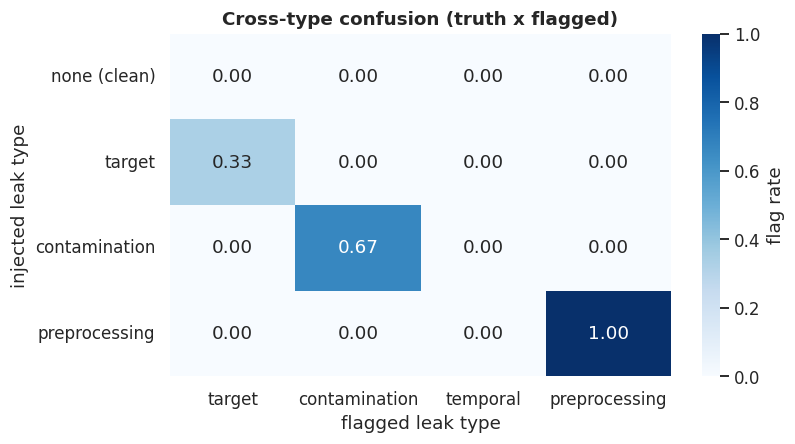


Blind spots: scenarios where the detection rate is below 50%

* target_L: detection rate 0.00 (n = 40, mean score 0.151)
  sigma = 1.0 makes the leak column only a weak label proxy (single-feature AUC ~ 0.76): weaker than the honest `median_income`, so MI, single-feature strength and ablation cannot separate it from genuine signal. A data-only detector that stays quiet on clean data must miss it.

* target_M: detection rate 0.00 (n = 40, mean score 0.375)
  sigma = 0.5 gives a single-feature AUC ~ 0.92, the same range as strong legitimate features (median_income, location). The `a - 0.85` offset and the ablation term that protect those features also suppress this leak: an inherent FPR/FNR trade-off.

* contam_L: detection rate 0.00 (n = 40, mean score 0.415)
  1% of the test rows is statistically significant but small: s_dup = clip(0.01 / 0.02) = 0.5 caps the score near 0.8 * 0.5 = 0.4 plus a small memorisation term, i.e. just below the 0.5 threshold. Tiny contamination also inflates 

In [30]:
# ===================================================================
# Cell 31 — Cross-type confusion and blind spots
# ===================================================================
res["truth_type"] = res["leak_type_true"].replace({"none": "none (clean)"})
type_order = ["none (clean)", "target", "contamination", "preprocessing"]
flag_cols = {t: f"flag_{t}" for t in CFG["LEAK_TYPES"]}
conf_mat = (res.groupby("truth_type")[list(flag_cols.values())].mean().reindex(type_order))
conf_mat.columns = list(flag_cols)
print("Mean flag rate: rows = injected leak type, columns = flagged type (mean over seeds and models):")
display(conf_mat.round(3))
conf_mat.to_csv(os.path.join(TABLE_DIR, "cross_type_confusion.csv"))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(conf_mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "flag rate"})
ax.set_title("Cross-type confusion (truth x flagged)"); ax.set_xlabel("flagged leak type"); ax.set_ylabel("injected leak type")
plt.tight_layout(); plt.show()

EXPLAIN = {
    "target_L": "sigma = 1.0 makes the leak column only a weak label proxy (single-feature AUC ~ 0.76): weaker than the honest `median_income`, so MI, "
                "single-feature strength and ablation cannot separate it from genuine signal. A data-only detector that stays quiet on clean data must miss it.",
    "target_M": "sigma = 0.5 gives a single-feature AUC ~ 0.92, the same range as strong legitimate features (median_income, location). The `a - 0.85` offset and the "
                "ablation term that protect those features also suppress this leak: an inherent FPR/FNR trade-off.",
    "target_H": "sigma = 0.15 is a near-perfect label proxy; if this is missed, check the calibrated threshold (cell 24) and the model-level permutation share.",
    "contam_L": "1% of the test rows is statistically significant but small: s_dup = clip(0.01 / 0.02) = 0.5 caps the score near 0.8 * 0.5 = 0.4 plus a small "
                "memorisation term, i.e. just below the 0.5 threshold. Tiny contamination also inflates performance very little.",
    "contam_M": "5% contamination: near copies (perturbed by 0.005 std) can fall outside the nearest-neighbour radius eps (5% quantile of within-train NN distances), "
                "so the excess is under-counted when the data are dense.",
    "contam_H": "20% contamination should be detected; a miss points to a too-small NN radius (dense data) or an over-raised calibrated threshold.",
    "prep_L": "Scaler fingerprint relies on exact mean/std; it fails only if the processed data were re-rounded or re-scaled after the pipeline.",
    "prep_M": "Imputation fingerprint needs a visible spike of imputed values (1-80% of a column); without missing values there is nothing to fingerprint.",
    "prep_H": "Encoder fingerprint needs a frequency-encoded column with <= 10 distinct values in (0, 1].",
}
blind = by_scn[by_scn.detection_rate < 0.5].copy()
print("\nBlind spots: scenarios where the detection rate is below 50%")
if blind.empty:
    print("  none - every injected scenario is detected in at least half of the runs.")
for r in blind.itertuples():
    print(f"\n* {r.scenario}: detection rate {r.detection_rate:.2f} (n = {r.n}, mean score {r.mean_score:.3f})\n  {EXPLAIN.get(r.scenario, 'No pre-written explanation.')}")
# a second look at partial misses (50% <= rate < 90%)
partial = by_scn[(by_scn.detection_rate >= 0.5) & (by_scn.detection_rate < 0.9)]
if len(partial):
    print("\nPartial detection (50-90%):", {r.scenario: round(r.detection_rate, 2) for r in partial.itertuples()})

Validation-minus-test AUC gap per scenario (averaged over models and seeds):


,scenario,leak_type,mean_gap_val_minus_test,std,shift_vs_clean,p_value,exposed_by_validation
0,clean,none,0.0010,0.0033,0.0000,NaN,False
1,target_L,target,0.0012,0.0039,0.0003,0.4047,False
2,target_M,target,0.0005,0.0019,-0.0005,0.3197,False
3,target_H,target,0.0001,0.0003,-0.0009,0.1021,False
4,contam_L,contamination,0.0007,0.0033,-0.0003,0.0062,False
5,contam_M,contamination,-0.0000,0.0036,-0.0010,0.0000,False
6,contam_H,contamination,-0.0032,0.0054,-0.0042,0.0000,True
7,prep_L,preprocessing,0.0011,0.0035,0.0001,0.4288,False
8,prep_M,preprocessing,0.0010,0.0035,0.0000,0.9463,False


By model:


model,logreg,mlp,rf,xgb
scenario,,,,
clean,0.0019,0.0009,0.0003,0.0009
target_L,0.0022,0.0015,0.0004,0.0010
target_M,0.0008,0.0004,0.0003,0.0005
target_H,0.0001,0.0004,0.0000,0.0000
contam_L,0.0017,0.0005,-0.0001,0.0005
contam_M,0.0019,0.0006,-0.0021,-0.0006
contam_H,0.0017,-0.0010,-0.0097,-0.0039
prep_L,0.0019,0.0012,0.0003,0.0009
prep_M,0.0019,0.0011,0.0002,0.0007



Exposed by a held-out validation set : ['contam_H']
NOT exposed (validation shares the leak or the pipeline): ['target_L', 'target_M', 'target_H', 'contam_L', 'contam_M', 'prep_L', 'prep_M']


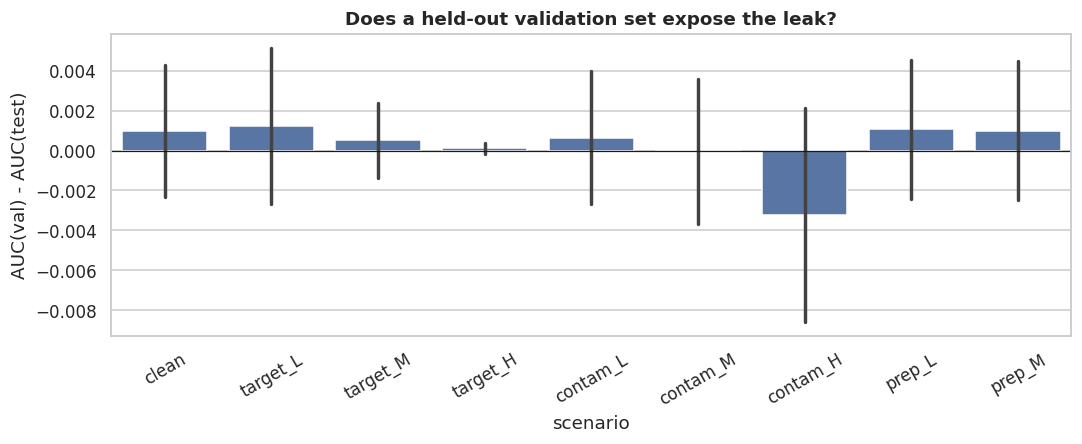

In [31]:
# ===================================================================
# Cell 32 — Practitioner check: does a held-out VALIDATION set expose the leak?  (auc_val - auc_test)
#   contamination copies TEST rows into train, so validation is honest while the test score is inflated  -> gap < 0
#   target / preprocessing leaks are shared by validation (same column / same pipeline)                  -> gap ~ clean
#   (XGBoost uses the validation set for early stopping, which makes its val AUC very slightly optimistic.)
# ===================================================================
res["gap_val_test"] = res["auc_val"] - res["auc_test"]
clean_gap = res[res.scenario == "clean"].set_index(["seed", "model"])["gap_val_test"]
prac_rows = []
for sid in ACTIVE_SCENARIOS:
    sub = res[res.scenario == sid].set_index(["seed", "model"])["gap_val_test"]
    diff = (sub - clean_gap.reindex(sub.index)).dropna()
    p = stats.ttest_1samp(diff, 0.0).pvalue if (sid != "clean" and len(diff) > 2 and diff.std() > 0) else np.nan
    prac_rows.append(dict(scenario=sid, leak_type=CFG["SCENARIOS"][sid]["type"], mean_gap_val_minus_test=sub.mean(), std=sub.std(),
                          shift_vs_clean=diff.mean() if sid != "clean" else 0.0, p_value=p,
                          exposed_by_validation=bool(sid != "clean" and np.isfinite(p) and p < 0.01 and diff.mean() < -0.002)))
prac = pd.DataFrame(prac_rows)
print("Validation-minus-test AUC gap per scenario (averaged over models and seeds):")
display(prac.round(4))
print("By model:")
display(res.pivot_table(index="scenario", columns="model", values="gap_val_test", aggfunc="mean").reindex(ACTIVE_SCENARIOS).round(4))
exposed = prac[prac.exposed_by_validation].scenario.tolist()
hidden = prac[(prac.scenario != "clean") & (~prac.exposed_by_validation)].scenario.tolist()
print(f"\nExposed by a held-out validation set : {exposed or 'none'}")
print(f"NOT exposed (validation shares the leak or the pipeline): {hidden or 'none'}")
prac.to_csv(os.path.join(TABLE_DIR, "practitioner_val_vs_test.csv"), index=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
sns.barplot(data=res, x="scenario", y="gap_val_test", order=ACTIVE_SCENARIOS, errorbar="sd", color="#4C72B0", ax=ax)
ax.axhline(0, color="k", lw=0.8); ax.set(ylabel="AUC(val) - AUC(test)", title="Does a held-out validation set expose the leak?")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

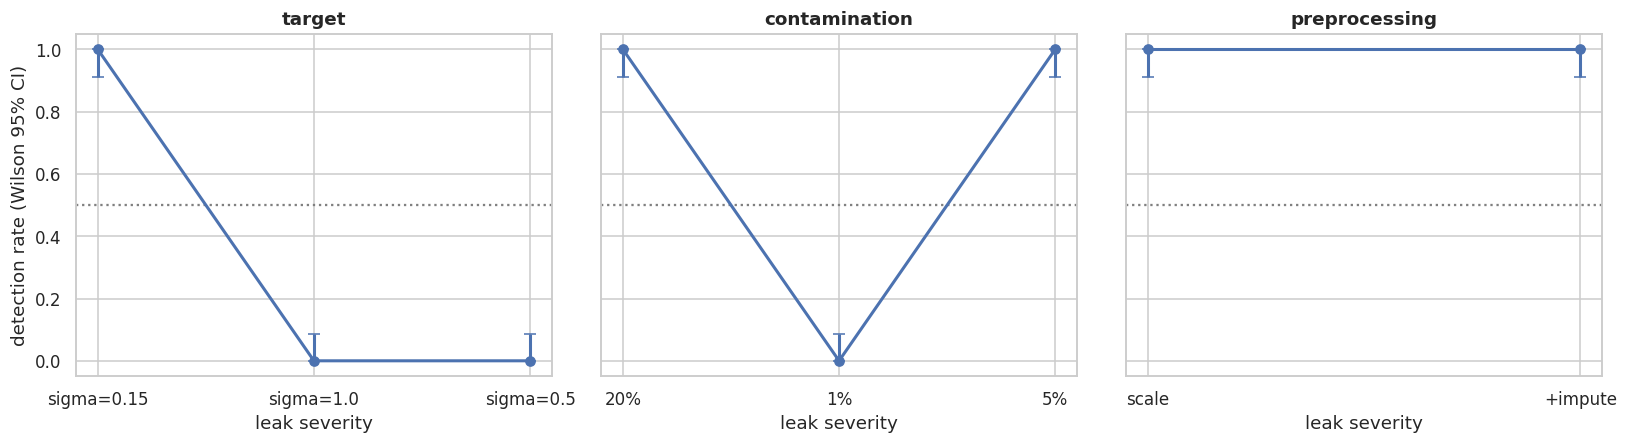

### Limits of pipeline-free detection (numbers from this run)
* **Target leakage**: detection rate falls from 1.00 at sigma = 0.15 to 0.00 at sigma = 1.0 (FNR 0.00 -> 1.00); mean AUC inflation shrinks from +0.0553 to +0.0117.
* **Tiny contamination** (1% of test rows, all exact): detection rate 0.00, FNR 1.00, true AUC inflation only -0.0004; at 20% the rate is 1.00 with +0.0037 AUC inflation.
* **Preprocessing leakage**: detection rates prep_L 1.00, prep_M 1.00; true AUC inflation prep_L -0.00017, prep_M -0.00027 - essentially invisible to performance, but exactly fingerprinted in the processed arrays.


**Conclusion — what stays hidden, and why**

1. **Weak or subtle target leaks.** A noisy label proxy looks like any other legitimate predictive feature. From the data and a black box alone there is no way to tell *“this feature is informative”* from *“this feature was derived from the label”* — the detector can only say *“this feature is suspiciously strong”*. Thresholds that keep the clean-data false-positive rate at zero (cell 24) necessarily miss moderate leaks, and these are also the leaks that inflate performance least.
2. **Tiny contamination.** One percent of test rows duplicated in train is statistically detectable by exact hashing, but the evidence is small, the score saturates below the threshold, and the inflation it causes is small as well.
3. **Near-duplicates in dense data.** The nearest-neighbour radius is calibrated on honest within-train distances; in dense regions (many near-identical blocks) it shrinks, so slightly perturbed copies can fall outside it.
4. **Preprocessing leakage is a blind spot for performance-based checks, not for fingerprints.** Because the processed arrays carry the exact fingerprint of the fit scope, the leak is found precisely — but only because the arrays are *exactly* what the pipeline produced (no re-rounding, no later re-scaling) and because there is a column to fingerprint (a scale step, an imputation spike, an encoded column). Its performance effect is near zero, so it cannot be seen through train/validation/test gaps.
5. **Natural spatial dependence is not injected leakage.** Neighbouring blocks in a random split make the `clean` scenario optimistic too (cell 34); no pipeline-free detector can, or should, flag that as one of the four leak types.


In [32]:
# ===================================================================
# Cell 33 — Limits of pipeline-free detection: detection rate vs severity
# ===================================================================
SEV_LABEL = {"target": {"L": "sigma=1.0", "M": "sigma=0.5", "H": "sigma=0.15"},
             "contamination": {"L": "1%", "M": "5%", "H": "20%"},
             "preprocessing": {"L": "scale", "M": "+impute", "H": "+encode"}}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, t in zip(axes, CFG["EVALUATED_TYPES"]):
    sub = by_scn[by_scn.leak_type == t].sort_values("severity")
    xs = [SEV_LABEL[t][s] for s in sub.severity]
    lo = [wilson_ci(int(round(r * n)), n)[0] for r, n in zip(sub.detection_rate, sub.n)]
    hi = [wilson_ci(int(round(r * n)), n)[1] for r, n in zip(sub.detection_rate, sub.n)]
    ax.errorbar(range(len(xs)), sub.detection_rate, yerr=[sub.detection_rate - lo, np.array(hi) - sub.detection_rate], marker="o", capsize=4, lw=2)
    ax.set_xticks(range(len(xs))); ax.set_xticklabels(xs); ax.set_ylim(-0.05, 1.05); ax.axhline(0.5, color="grey", ls=":")
    ax.set_title(t); ax.set_xlabel("leak severity")
axes[0].set_ylabel("detection rate (Wilson 95% CI)")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "08_detection_vs_severity.png"), bbox_inches="tight"); plt.show()

rate = by_scn.set_index("scenario")["detection_rate"]
fnr = by_scn.set_index("scenario")["FNR"]
infl_by_scn = leaky.groupby("scenario")["infl_auc"].mean()
lines = []
if {"target_L", "target_H"} <= set(rate.index):
    lines.append(f"* **Target leakage**: detection rate falls from {rate['target_H']:.2f} at sigma = 0.15 to {rate['target_L']:.2f} at sigma = 1.0 "
                 f"(FNR {fnr['target_H']:.2f} -> {fnr['target_L']:.2f}); mean AUC inflation shrinks from {infl_by_scn['target_H']:+.4f} to {infl_by_scn['target_L']:+.4f}.")
if "contam_L" in rate.index:
    lines.append(f"* **Tiny contamination** (1% of test rows, all exact): detection rate {rate['contam_L']:.2f}, FNR {fnr['contam_L']:.2f}, "
                 f"true AUC inflation only {infl_by_scn['contam_L']:+.4f}; at 20% the rate is {rate.get('contam_H', float('nan')):.2f} with {infl_by_scn.get('contam_H', float('nan')):+.4f} AUC inflation.")
prep_ids = [s for s in ("prep_L", "prep_M", "prep_H") if s in rate.index]
if prep_ids:
    lines.append("* **Preprocessing leakage**: detection rates " + ", ".join(f"{s} {rate[s]:.2f}" for s in prep_ids)
                 + "; true AUC inflation " + ", ".join(f"{s} {infl_by_scn[s]:+.5f}" for s in prep_ids)
                 + " - essentially invisible to performance, but exactly fingerprinted in the processed arrays.")
limits_summary = "\n".join(lines)
display(Markdown("### Limits of pipeline-free detection (numbers from this run)\n" + limits_summary))
display(Markdown("""
**Conclusion — what stays hidden, and why**

1. **Weak or subtle target leaks.** A noisy label proxy looks like any other legitimate predictive feature. From the data and a black box alone there is no way to tell *“this feature is informative”* from *“this feature was derived from the label”* — the detector can only say *“this feature is suspiciously strong”*. Thresholds that keep the clean-data false-positive rate at zero (cell 24) necessarily miss moderate leaks, and these are also the leaks that inflate performance least.
2. **Tiny contamination.** One percent of test rows duplicated in train is statistically detectable by exact hashing, but the evidence is small, the score saturates below the threshold, and the inflation it causes is small as well.
3. **Near-duplicates in dense data.** The nearest-neighbour radius is calibrated on honest within-train distances; in dense regions (many near-identical blocks) it shrinks, so slightly perturbed copies can fall outside it.
4. **Preprocessing leakage is a blind spot for performance-based checks, not for fingerprints.** Because the processed arrays carry the exact fingerprint of the fit scope, the leak is found precisely — but only because the arrays are *exactly* what the pipeline produced (no re-rounding, no later re-scaling) and because there is a column to fingerprint (a scale step, an imputation spike, an encoded column). Its performance effect is near zero, so it cannot be seen through train/validation/test gaps.
5. **Natural spatial dependence is not injected leakage.** Neighbouring blocks in a random split make the `clean` scenario optimistic too (cell 34); no pipeline-free detector can, or should, flag that as one of the four leak types.
"""))
by_scn.to_csv(os.path.join(TABLE_DIR, "detection_by_scenario.csv"), index=False)

Detector on the combined leaky scenario: {'target': (0.776, True), 'contamination': (0.8, True), 'preprocessing': (1.0, True)}
Suspect features: ['leak_feat'] | reported duplicates: 413 exact + 535 near
Detector-guided remediation: removed 948 train rows and columns ['leak_feat'];  oracle remediation: 826 rows and ['leak_feat'].

Test AUC: clean baseline vs leaky vs remediated (seed 0):


,clean_baseline,leaky,remediated_detector_guided,remediated_oracle,inflation_before,inflation_after (detector),inflation_after (oracle)
model,,,,,,,
Logistic Regression,0.9122,0.9998,0.9122,0.9122,0.0876,0.0000,0.0000
Random Forest,0.9550,1.0000,0.9552,0.9548,0.0450,0.0002,-0.0002
XGBoost,0.9646,1.0000,0.9635,0.9640,0.0354,-0.0011,-0.0007
MLP,0.9371,0.9990,0.9350,0.9336,0.0619,-0.0021,-0.0035


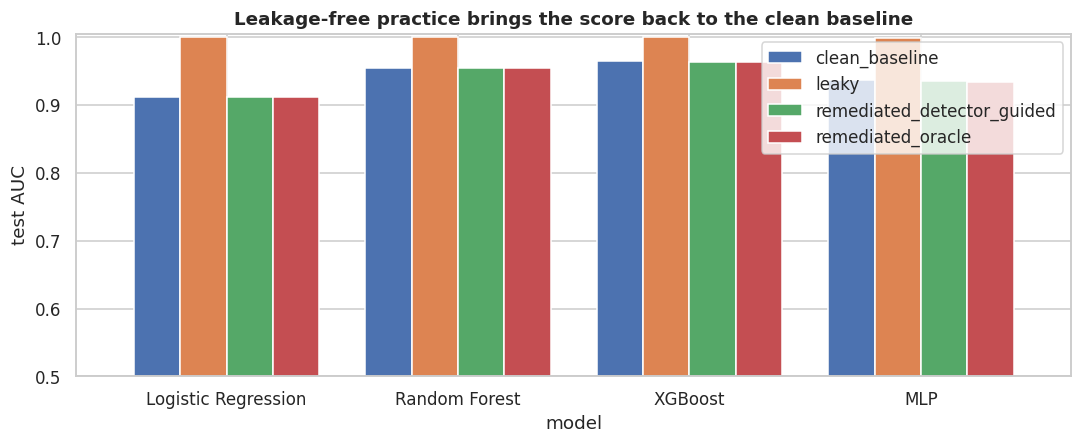


Spatial blocks: 59 populated cells of a 10 x 10 longitude/latitude grid.

Random 5-fold CV vs spatial-block 5-fold CV (clean data, AUC):


,random_cv_auc,random_std,spatial_cv_auc,spatial_std,optimism
model,,,,,
Logistic Regression,0.9138,0.0064,0.9068,0.0397,0.0070
Random Forest,0.9606,0.0011,0.9126,0.0230,0.0479
XGBoost,0.9691,0.0008,0.9216,0.0199,0.0474
MLP,0.9447,0.0021,0.9165,0.0159,0.0282


-> Mean optimism of a random split on geographic data: +0.0327 AUC (natural spatial dependence, NOT one of the four injected leak types).


In [33]:
# ===================================================================
# Cell 34 — Leakage-free practice demo
#   (a) one leaky scenario with ALL three leaks -> detect -> remediate (de-duplicate, drop flagged features,
#       fit preprocessing on train only) -> re-train the 4 models -> the score returns to the clean baseline
#   (b) random 5-fold CV vs spatial-block CV on the clean data: the natural spatial optimism of a random split
# ===================================================================
DEMO_SEED = 0
demo_scopes = dict(scale="pool", impute="pool", **({"encode": "pool"} if HAS_CATEGORICAL else {}))
demo_spec = dict(sigma=0.15, p=0.20, near_frac=0.5, scopes=demo_scopes)
leaky_scn = build_from_spec(DEMO_SEED, demo_spec, "demo_all_three")
clean_demo = build_scenario(DEMO_SEED, "clean")

def remediate_arrays(scn, dup_train_ids, drop_cols):
    """De-duplicate train, drop columns, refit ALL preprocessing on train only."""
    tr, va, te = scn.raw_train, scn.raw_val, scn.raw_test
    if len(dup_train_ids):
        tr = tr[~tr["row_id"].isin(set(dup_train_ids))].reset_index(drop=True)
    drop_cols = [c for c in drop_cols if c in tr.columns]
    tr, va, te = tr.drop(columns=drop_cols), va.drop(columns=drop_cols), te.drop(columns=drop_cols)
    pipe = Pipeline().fit(tr, te)                                        # every scope = train
    return ScenarioData(scenario_id="remediated", seed=scn.seed, X_train=pipe.transform(tr), y_train=tr["y"].to_numpy(),
                        X_val=pipe.transform(va), y_val=va["y"].to_numpy(), X_test=pipe.transform(te), y_test=te["y"].to_numpy(),
                        feature_names=list(pipe.feature_names), row_id_train=tr["row_id"].to_numpy(), row_id_test=te["row_id"].to_numpy(),
                        meta={}, truth={}, pipeline=pipe)

# detector on the leaky scenario (XGBoost as the black box)
bb_demo, met_demo = train_and_eval(leaky_scn, "xgb")
rep_demo = detector_for(leaky_scn, bb_demo, thresholds=CFG["THRESH"]).run()
flagged_demo = [t for t in CFG["EVALUATED_TYPES"] if rep_demo[t]["flag"]]
print("Detector on the combined leaky scenario:", {t: (round(rep_demo[t]["score"], 3), rep_demo[t]["flag"]) for t in CFG["EVALUATED_TYPES"]})
print("Suspect features:", rep_demo["target"]["evidence"]["suspect_features"], "| reported duplicates:",
      rep_demo["contamination"]["evidence"]["n_exact"], "exact +", rep_demo["contamination"]["evidence"]["n_near"], "near")

strip = lambda names: [n[:-5] if n.endswith("_freq") else n for n in names]
det_dup = rep_demo["contamination"]["evidence"]["dup_train_row_ids"] if rep_demo["contamination"]["flag"] else []
det_drop = strip(rep_demo["target"]["evidence"]["suspect_features"]) if rep_demo["target"]["flag"] else []
orc_dup = leaky_scn.meta["contamination"]["dup_train_row_ids"]
orc_drop = ["leak_feat"]
scn_detect = remediate_arrays(leaky_scn, det_dup, det_drop)             # detector-guided remediation
scn_oracle = remediate_arrays(leaky_scn, orc_dup, orc_drop)             # ground-truth remediation (reference)
print(f"Detector-guided remediation: removed {len(det_dup)} train rows and columns {det_drop or 'none'};  "
      f"oracle remediation: {len(orc_dup)} rows and {orc_drop}.")

demo_rows = []
for name in CFG["MODELS"]:
    _, m_leaky = train_and_eval(leaky_scn, name)
    _, m_det = train_and_eval(scn_detect, name)
    _, m_orc = train_and_eval(scn_oracle, name)
    _, m_cl = train_and_eval(clean_demo, name)
    demo_rows.append(dict(model=MODEL_LABELS[name], clean_baseline=m_cl["auc_test"], leaky=m_leaky["auc_test"],
                          remediated_detector_guided=m_det["auc_test"], remediated_oracle=m_orc["auc_test"]))
demo = pd.DataFrame(demo_rows).set_index("model")
demo["inflation_before"] = demo["leaky"] - demo["clean_baseline"]
demo["inflation_after (detector)"] = demo["remediated_detector_guided"] - demo["clean_baseline"]
demo["inflation_after (oracle)"] = demo["remediated_oracle"] - demo["clean_baseline"]
print("\nTest AUC: clean baseline vs leaky vs remediated (seed 0):")
display(demo.round(4))
demo.to_csv(os.path.join(TABLE_DIR, "remediation_demo.csv"))

ax = demo[["clean_baseline", "leaky", "remediated_detector_guided", "remediated_oracle"]].plot(kind="bar", figsize=(10, 4.2), width=0.8)
ax.set_ylim(max(0.5, demo.min().min() - 0.03), 1.005); ax.set_ylabel("test AUC"); ax.set_title("Leakage-free practice brings the score back to the clean baseline")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "09_remediation_demo.png"), bbox_inches="tight"); plt.show()

# ---- (b) random vs spatial-block cross-validation on the CLEAN data ------------------------------------------
lon_bin = pd.cut(data["longitude"], 10, labels=False).to_numpy()
lat_bin = pd.cut(data["latitude"], 10, labels=False).to_numpy()
groups = lon_bin * 10 + lat_bin
print(f"\nSpatial blocks: {len(np.unique(groups))} populated cells of a 10 x 10 longitude/latitude grid.")

def cv_auc(name, splits, seed=0):
    out = []
    for tr, te in splits:
        trd, ted = data.iloc[tr], data.iloc[te]
        pipe = Pipeline().fit(trd, ted)                                  # preprocessing fitted on the training fold only
        Xtr, Xte, ytr, yte = pipe.transform(trd), pipe.transform(ted), trd["y"].to_numpy(), ted["y"].to_numpy()
        Xa, Xv, ya, yv = train_test_split(Xtr, ytr, test_size=0.1, stratify=ytr, random_state=seed)   # inner val (XGBoost early stopping)
        m = fit_model(name, Xa, ya, Xv, yv, seed)
        out.append(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]))
    return float(np.mean(out)), float(np.std(out))

idx_all = np.arange(len(data))
rand_splits = list(KFold(5, shuffle=True, random_state=0).split(idx_all))
spat_splits = list(GroupKFold(5).split(idx_all, groups=groups))
cv_rows = []
for name in CFG["MODELS"]:
    r_m, r_s = cv_auc(name, rand_splits)
    s_m, s_s = cv_auc(name, spat_splits)
    cv_rows.append(dict(model=MODEL_LABELS[name], random_cv_auc=r_m, random_std=r_s, spatial_cv_auc=s_m, spatial_std=s_s, optimism=r_m - s_m))
cv_tbl = pd.DataFrame(cv_rows).set_index("model")
print("\nRandom 5-fold CV vs spatial-block 5-fold CV (clean data, AUC):")
display(cv_tbl.round(4))
print(f"-> Mean optimism of a random split on geographic data: {cv_tbl['optimism'].mean():+.4f} AUC "
      "(natural spatial dependence, NOT one of the four injected leak types).")
cv_tbl.to_csv(os.path.join(TABLE_DIR, "random_vs_spatial_cv.csv"))

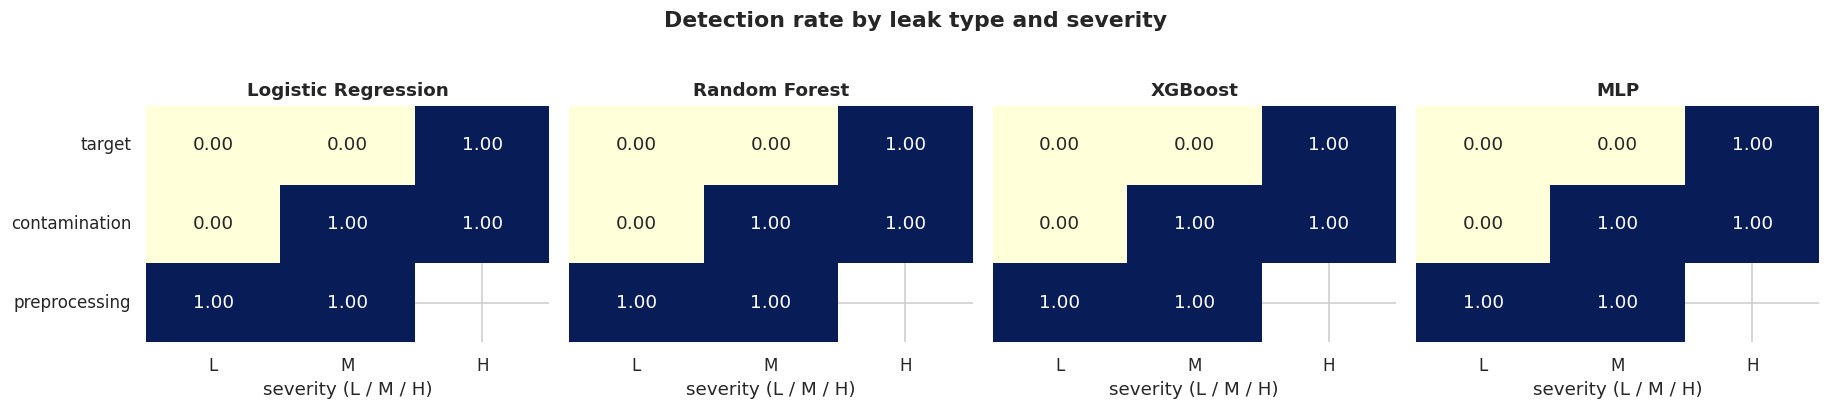

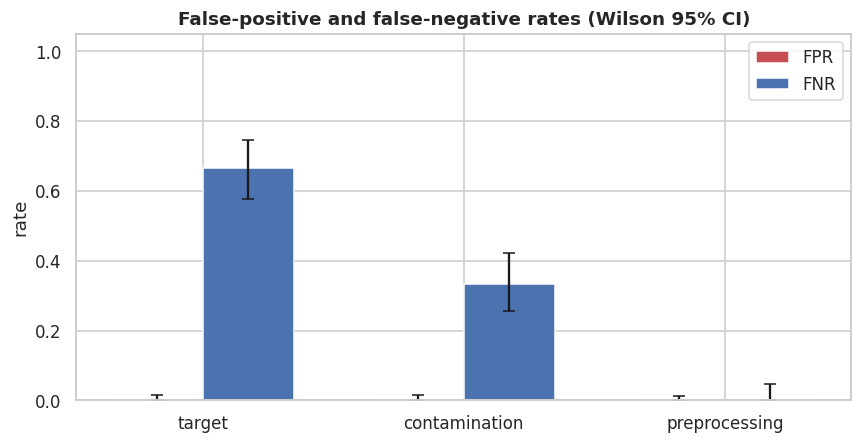

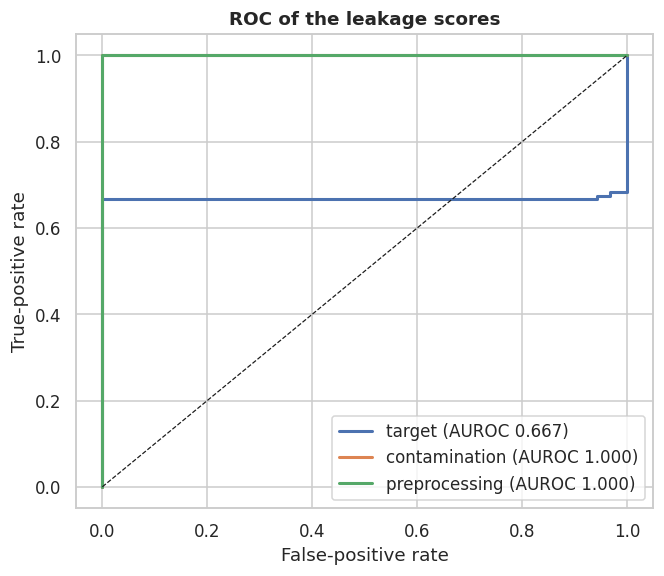

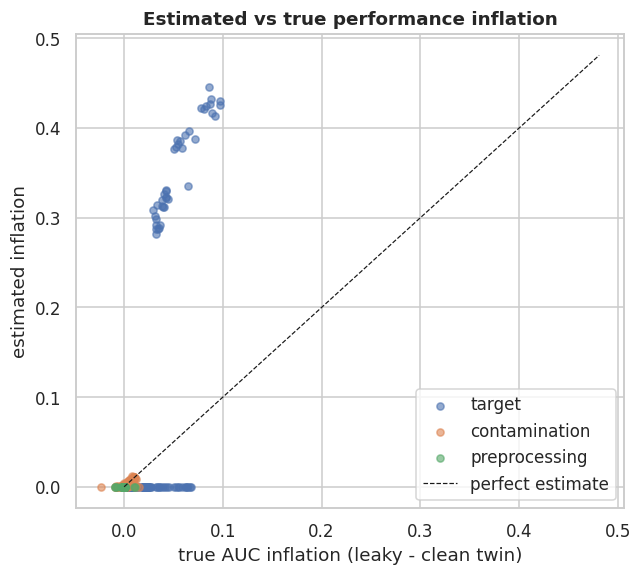

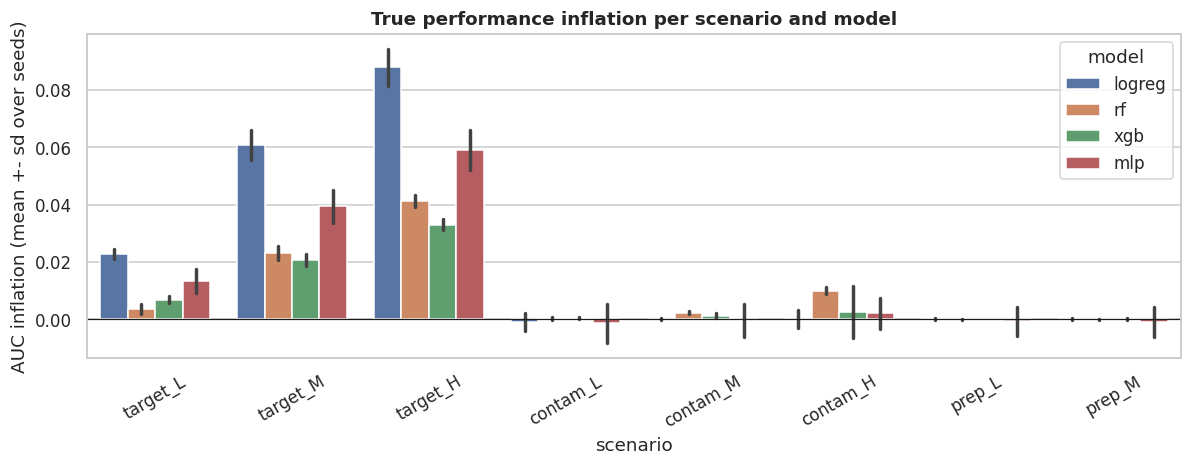

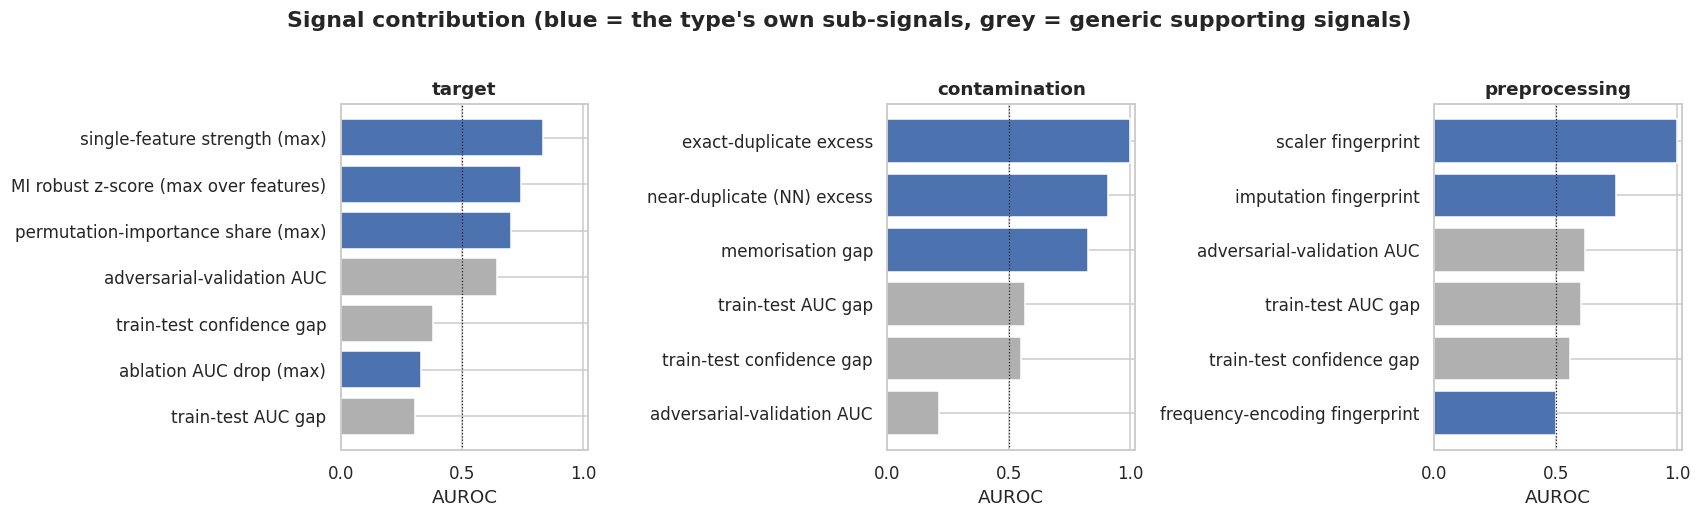

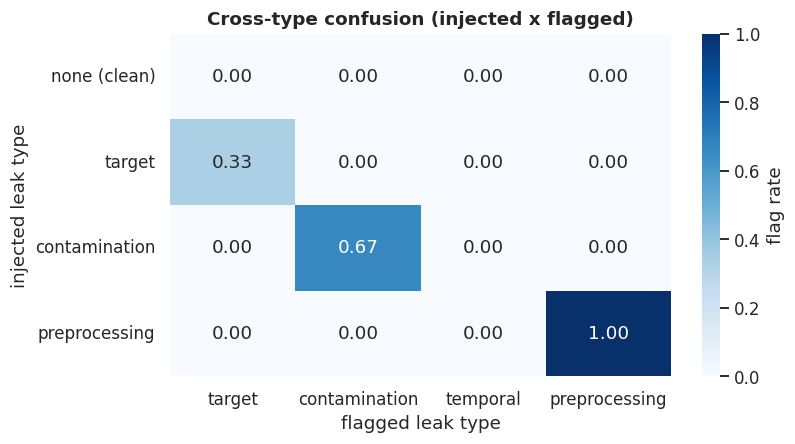

Figures saved to /content/results/figures : ['00_clean_baseline_roc.png', '00_eda.png', '01_detection_rate_heatmap.png', '02_fpr_fnr.png', '03_score_roc.png', '04_est_vs_true_inflation.png', '05_true_inflation_bars.png', '06_signal_contribution.png', '07_cross_type_confusion.png', '08_detection_vs_severity.png', '09_remediation_demo.png']


In [34]:
# ===================================================================
# Cell 35 — Figures (PNG in results/figures/)
# ===================================================================
def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), bbox_inches="tight"); plt.show()

TYPES = CFG["EVALUATED_TYPES"]
SEVS = ["L", "M", "H"]

# 1. detection-rate heatmap (leak type x severity) per model
fig, axes = plt.subplots(1, len(CFG["MODELS"]), figsize=(4.2 * len(CFG["MODELS"]), 3.6), sharey=True)
for ax, m in zip(np.atleast_1d(axes), CFG["MODELS"]):
    grid = pd.DataFrame(index=TYPES, columns=SEVS, dtype=float)
    for sid in [s for s in ACTIVE_SCENARIOS if s != "clean"]:
        t, v = CFG["SCENARIOS"][sid]["type"], CFG["SCENARIOS"][sid]["variant"]
        sub = res[(res.scenario == sid) & (res.model == m)]
        grid.loc[t, v] = sub[f"flag_{t}"].mean()
    sns.heatmap(grid, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1, ax=ax, cbar=False)
    ax.set_title(MODEL_LABELS[m]); ax.set_xlabel("severity (L / M / H)"); ax.set_ylabel("")
fig.suptitle("Detection rate by leak type and severity", y=1.03, fontweight="bold")
savefig("01_detection_rate_heatmap.png")

# 2. FPR / FNR per type with Wilson CIs
fig, ax = plt.subplots(figsize=(8, 4.2))
w = 0.35
for k, (metric, colr) in enumerate([("FPR", "#C44E52"), ("FNR", "#4C72B0")]):
    vals = det_tbl.loc[TYPES, metric].to_numpy(float)
    lo, hi = det_tbl.loc[TYPES, f"{metric}_lo"].to_numpy(float), det_tbl.loc[TYPES, f"{metric}_hi"].to_numpy(float)
    ax.bar(np.arange(len(TYPES)) + (k - 0.5) * w, vals, w, yerr=[vals - lo, hi - vals], capsize=4, label=metric, color=colr)
ax.set_xticks(range(len(TYPES))); ax.set_xticklabels(TYPES); ax.set_ylim(0, 1.05); ax.set_ylabel("rate")
ax.set_title("False-positive and false-negative rates (Wilson 95% CI)"); ax.legend()
savefig("02_fpr_fnr.png")

# 3. ROC curves of the leakage scores
fig, ax = plt.subplots(figsize=(6.2, 5.4))
for t in TYPES:
    y = res[f"truth_{t}"].to_numpy(bool)
    if 0 < y.sum() < len(y):
        fpr, tpr, _ = roc_curve(y, res[f"score_{t}"])
        ax.plot(fpr, tpr, lw=2, label=f"{t} (AUROC {roc_auc_score(y, res[f'score_{t}']):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8); ax.set(xlabel="False-positive rate", ylabel="True-positive rate", title="ROC of the leakage scores")
ax.legend(loc="lower right")
savefig("03_score_roc.png")

# 4. estimated vs true inflation
fig, ax = plt.subplots(figsize=(6, 5.4))
for t in TYPES:
    sub = leaky[leaky.leak_type_true == t]
    ax.scatter(sub["true_infl"], sub["est_own"], s=22, alpha=0.6, label=t)
lim = max(leaky["true_infl"].max(), leaky["est_own"].max(), 0.01) * 1.08
ax.plot([0, lim], [0, lim], "k--", lw=0.8, label="perfect estimate")
ax.set(xlabel="true AUC inflation (leaky - clean twin)", ylabel="estimated inflation", title="Estimated vs true performance inflation")
ax.legend()
savefig("04_est_vs_true_inflation.png")

# 5. true inflation bars per scenario x model
fig, ax = plt.subplots(figsize=(11, 4.4))
sns.barplot(data=leaky, x="scenario", y="infl_auc", hue="model", order=[s for s in ACTIVE_SCENARIOS if s != "clean"],
            hue_order=CFG["MODELS"], errorbar="sd", ax=ax)
ax.axhline(0, color="k", lw=0.8); ax.set(ylabel="AUC inflation (mean +- sd over seeds)", title="True performance inflation per scenario and model")
plt.xticks(rotation=30)
savefig("05_true_inflation_bars.png")

# 6. signal contribution
fig, axes = plt.subplots(1, len(TYPES), figsize=(5.2 * len(TYPES), 4.6), sharex=True)
for ax, t in zip(np.atleast_1d(axes), TYPES):
    sub = sig_tbl[sig_tbl.leak_type == t].sort_values("AUROC")
    ax.barh(sub["signal"], sub["AUROC"], color=["#4C72B0" if r == "own" else "#B0B0B0" for r in sub["role"]])
    ax.axvline(0.5, color="k", lw=0.8, ls=":"); ax.set_xlim(0, 1.02); ax.set_title(t); ax.set_xlabel("AUROC")
fig.suptitle("Signal contribution (blue = the type's own sub-signals, grey = generic supporting signals)", y=1.02, fontweight="bold")
savefig("06_signal_contribution.png")

# 7. cross-type confusion
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(conf_mat, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "flag rate"})
ax.set(title="Cross-type confusion (injected x flagged)", xlabel="flagged leak type", ylabel="injected leak type")
savefig("07_cross_type_confusion.png")
print("Figures saved to", FIG_DIR, ":", sorted(os.listdir(FIG_DIR)))

In [35]:
# ===================================================================
# Cell 36 — Export and conclusions
# ===================================================================
import shutil
# results.csv / results_with_inflation.csv / thresholds.json already live in RESULTS_DIR; the tables were saved by cells 27-34
pd.DataFrame([dict(scenario=s, **{f"score_{t}": g[f"score_{t}"].mean() for t in CFG["EVALUATED_TYPES"]},
                   **{f"flag_{t}": g[f"flag_{t}"].mean() for t in CFG["EVALUATED_TYPES"]}) for s, g in res.groupby("scenario")]
             ).to_csv(os.path.join(TABLE_DIR, "mean_scores_by_scenario.csv"), index=False)
zip_path = shutil.make_archive(os.path.join(ROOT, "leakage_results"), "zip", RESULTS_DIR)
print("Files in results/:", sorted(os.listdir(RESULTS_DIR)))
print("Tables:", sorted(os.listdir(TABLE_DIR)))
print("Zip archive:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)              # browser download only (no Google Drive)
except ImportError:
    print("(Not running in Colab: the zip stays at the path above.)")

# ---------- conclusions with the numbers of THIS run ----------
f = lambda x: "n/a" if not np.isfinite(x) else f"{x:.3f}"
lines = []
for t in CFG["EVALUATED_TYPES"]:
    r = det_tbl.loc[t]
    lines.append(f"| {t} | {f(r['accuracy'])} | {f(r['FPR'])} | {f(r['FNR'])} | {f(r['precision'])} | {f(r['recall'])} | "
                 f"{by_type_mean.get(t, float('nan')):+.4f} | {f(auroc_tbl.loc[t, 'AUROC'])} |")
ov = det_tbl.loc["OVERALL verdict"]
best_sig = {t: f"{best[t]['signal']} (AUROC {best[t]['AUROC']:.2f})" for t in CFG["EVALUATED_TYPES"]}
blind_txt = ", ".join(f"`{r.scenario}` ({r.detection_rate:.0%})" for r in blind.itertuples()) or "none"
rem = demo.loc[:, ["inflation_before", "inflation_after (detector)", "inflation_after (oracle)"]].mean()
display(Markdown(f"""
## Conclusions (numbers computed from this run: {len(CFG['EVAL_SEEDS'])} seeds x {len(ACTIVE_SCENARIOS)} scenarios x {len(CFG['MODELS'])} models = {len(res)} detector runs)

| leak type | accuracy | FPR | FNR | precision | recall | mean true AUC inflation | score AUROC |
|---|---|---|---|---|---|---|---|
{chr(10).join(lines)}
| **temporal** | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| **overall verdict (leaky vs clean)** | {f(ov['accuracy'])} | {f(ov['FPR'])} | {f(ov['FNR'])} | {f(ov['precision'])} | {f(ov['recall'])} | | |

* **Which signals mattered most.** Target: {best_sig['target']}; contamination: {best_sig['contamination']}; preprocessing: {best_sig['preprocessing']}. Adversarial validation and the train-test gaps are supporting signals only (weight 0); cell 29 shows how informative each is on its own.
* **Performance inflation.** Leak type ranking by mean true AUC inflation: {", ".join(f"{k} ({v:+.4f})" for k, v in by_type_mean.items())}. Preprocessing leakage barely changes any metric, so it is invisible to a train / validation / test comparison (cell 32) and is found only through exact fingerprints.
* **Limits of pipeline-free detection.** Blind spots in this run (detection rate < 50%): {blind_txt}. Weak or moderate target leaks are indistinguishable from legitimate strong features such as `median_income`; very small contamination is statistically visible but weak; near-duplicates depend on a data-adaptive radius. See cells 31 and 33.
* **Why temporal leakage was out of scope.** California Housing has no timestamp, so the temporal module abstained (`score = NaN`, `flag = False`) and is excluded from accuracy / FPR / FNR. The module itself is verified on synthetic timestamps in cell 17, outside the reported results. No time axis was invented.
* **Leakage-free recommendations** (cell 34): de-duplicate before splitting and drop train rows that duplicate test rows; question any feature that is suspiciously predictive; fit **all** preprocessing (scaler, imputer, encoder) on the training split only; use time-aware splits when a time axis exists; and use spatial-block validation for geographic data. On the combined leaky scenario the mean AUC inflation of {rem['inflation_before']:+.4f} dropped to {rem['inflation_after (detector)']:+.4f} with detector-guided remediation ({rem['inflation_after (oracle)']:+.4f} with ground-truth remediation). A random split of this geographic data is still optimistic by about {cv_tbl['optimism'].mean():+.4f} AUC relative to spatial-block CV — natural spatial dependence, not one of the four injected leaks.
* **Caveats.** The `clean` scenario is clean only with respect to the four injected leak types; Wilson intervals treat runs as independent although the four models of a scenario share data-level evidence; results come from one dataset and four controlled injections, so rates should not be read as universal detector accuracy.
"""))

Files in results/: ['figures', 'results.csv', 'results_with_inflation.csv', 'run_config.json', 'tables', 'thresholds.json']
Tables: ['cross_type_confusion.csv', 'detection_by_scenario.csv', 'detection_by_type_model.csv', 'detection_metrics.csv', 'estimated_vs_true_inflation.csv', 'evidence_contamination.csv', 'evidence_target.csv', 'mean_scores_by_scenario.csv', 'practitioner_val_vs_test.csv', 'random_vs_spatial_cv.csv', 'remediation_demo.csv', 'score_auroc.csv', 'signal_contribution.csv', 'true_inflation_acc.csv', 'true_inflation_auc.csv']
Zip archive: /content/leakage_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


## Conclusions (numbers computed from this run: 10 seeds x 9 scenarios x 4 models = 360 detector runs)

| leak type | accuracy | FPR | FNR | precision | recall | mean true AUC inflation | score AUROC |
|---|---|---|---|---|---|---|---|
| target | 0.778 | 0.000 | 0.667 | 1.000 | 0.333 | +0.0343 | 0.667 |
| contamination | 0.889 | 0.000 | 0.333 | 1.000 | 0.667 | +0.0014 | 1.000 |
| preprocessing | 1.000 | 0.000 | 0.000 | 1.000 | 1.000 | -0.0002 | 1.000 |
| **temporal** | N/A | N/A | N/A | N/A | N/A | N/A | N/A |
| **overall verdict (leaky vs clean)** | 0.667 | 0.000 | 0.375 | 1.000 | 0.625 | | |

* **Which signals mattered most.** Target: single-feature strength (max) (AUROC 0.84); contamination: exact-duplicate excess (AUROC 1.00); preprocessing: scaler fingerprint (AUROC 1.00). Adversarial validation and the train-test gaps are supporting signals only (weight 0); cell 29 shows how informative each is on its own.
* **Performance inflation.** Leak type ranking by mean true AUC inflation: target (+0.0343), contamination (+0.0014), preprocessing (-0.0002). Preprocessing leakage barely changes any metric, so it is invisible to a train / validation / test comparison (cell 32) and is found only through exact fingerprints.
* **Limits of pipeline-free detection.** Blind spots in this run (detection rate < 50%): `target_L` (0%), `target_M` (0%), `contam_L` (0%). Weak or moderate target leaks are indistinguishable from legitimate strong features such as `median_income`; very small contamination is statistically visible but weak; near-duplicates depend on a data-adaptive radius. See cells 31 and 33.
* **Why temporal leakage was out of scope.** California Housing has no timestamp, so the temporal module abstained (`score = NaN`, `flag = False`) and is excluded from accuracy / FPR / FNR. The module itself is verified on synthetic timestamps in cell 17, outside the reported results. No time axis was invented.
* **Leakage-free recommendations** (cell 34): de-duplicate before splitting and drop train rows that duplicate test rows; question any feature that is suspiciously predictive; fit **all** preprocessing (scaler, imputer, encoder) on the training split only; use time-aware splits when a time axis exists; and use spatial-block validation for geographic data. On the combined leaky scenario the mean AUC inflation of +0.0575 dropped to -0.0008 with detector-guided remediation (-0.0011 with ground-truth remediation). A random split of this geographic data is still optimistic by about +0.0327 AUC relative to spatial-block CV — natural spatial dependence, not one of the four injected leaks.
* **Caveats.** The `clean` scenario is clean only with respect to the four injected leak types; Wilson intervals treat runs as independent although the four models of a scenario share data-level evidence; results come from one dataset and four controlled injections, so rates should not be read as universal detector accuracy.
